# **AMR CLASSIFICATION FROM FLUORESCENCE MICROSCOPY IMAGES**

## **Environment Setup & Imports**

In [1]:
import os
import shutil
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import cv2
import tifffile
import tensorflow as tf

from PIL import Image
from scipy import ndimage as ndi
from skimage import filters, morphology, measure
from skimage.segmentation import clear_border, watershed
from skimage.feature import peak_local_max
from skimage.color import label2rgb

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    roc_curve, auc, confusion_matrix,
    classification_report, cohen_kappa_score,
    matthews_corrcoef
)
from sklearn.preprocessing import LabelBinarizer

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense,
    BatchNormalization, Dropout, Input,
    GlobalAveragePooling2D, LayerNormalization,
    MultiHeadAttention, Add
)
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import DenseNet169, EfficientNetB0
from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)
from tensorflow.keras.metrics import F1Score
from tensorflow.keras.preprocessing.image import ImageDataGenerator

warnings.filterwarnings('ignore')

# Plotting style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.dpi': 100, 'font.size': 11})

## **Data Acquisition & Preparation**

In [2]:
url = "https://ora.ox.ac.uk/objects/uuid:12153432-e8b3-4398-a395-abfb980bd84e/files/rjw827c35g"
filename = "oxford_data.zip"

In [3]:
!wget -O {filename} {url}

--2026-06-25 06:15:01--  https://ora.ox.ac.uk/objects/uuid:12153432-e8b3-4398-a395-abfb980bd84e/files/rjw827c35g
Resolving ora.ox.ac.uk (ora.ox.ac.uk)... 172.66.159.143, 104.20.30.6, 2606:4700:10::ac42:9f8f, ...
Connecting to ora.ox.ac.uk (ora.ox.ac.uk)|172.66.159.143|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [application/zip]
Saving to: ‘oxford_data.zip’

oxford_data.zip         [         <=>        ]   4.83G  36.6MB/s    in 2m 20s  

2026-06-25 06:17:22 (35.3 MB/s) - ‘oxford_data.zip’ saved [5189672803]



In [4]:
if os.path.exists(filename):
    print(f"Dataset downloaded as {filename}")
else:
    print("Download failed. Check the URL.")

Dataset downloaded as oxford_data.zip


In [5]:
!unzip -q oxford_data.zip
print("Extraction complete.")

Extraction complete.


#### **Clean & Rename Folders**

In [6]:
raw_parent_dir = "Zagajewski_Data/Data/MG1655/All_images"
CLASSES = ['WT', 'CIP', 'GENT', 'RIF']

# Remove unwanted class
coamox_path = os.path.join(raw_parent_dir, "COAMOX+ETOH")
if os.path.exists(coamox_path):
    shutil.rmtree(coamox_path)
    print("Removed COAMOX+ETOH folder.")

Removed COAMOX+ETOH folder.


In [7]:
# Rename ethanol-suffixed folders
folder_names = ['WT+ETOH', 'CIP+ETOH', 'GENT+ETOH', 'RIF+ETOH']
for f in folder_names:
    old_name = os.path.join(raw_parent_dir, f)
    new_name = os.path.join(raw_parent_dir, f.split("+")[0])
    if os.path.exists(old_name):
        os.rename(old_name, new_name)
    count = len(os.listdir(new_name))
    print(f"  {new_name}: {count} images")

  Zagajewski_Data/Data/MG1655/All_images/WT: 455 images
  Zagajewski_Data/Data/MG1655/All_images/CIP: 285 images
  Zagajewski_Data/Data/MG1655/All_images/GENT: 199 images
  Zagajewski_Data/Data/MG1655/All_images/RIF: 279 images


## **Exploratory Data Analysis**

#### **Raw Image Count per Class**

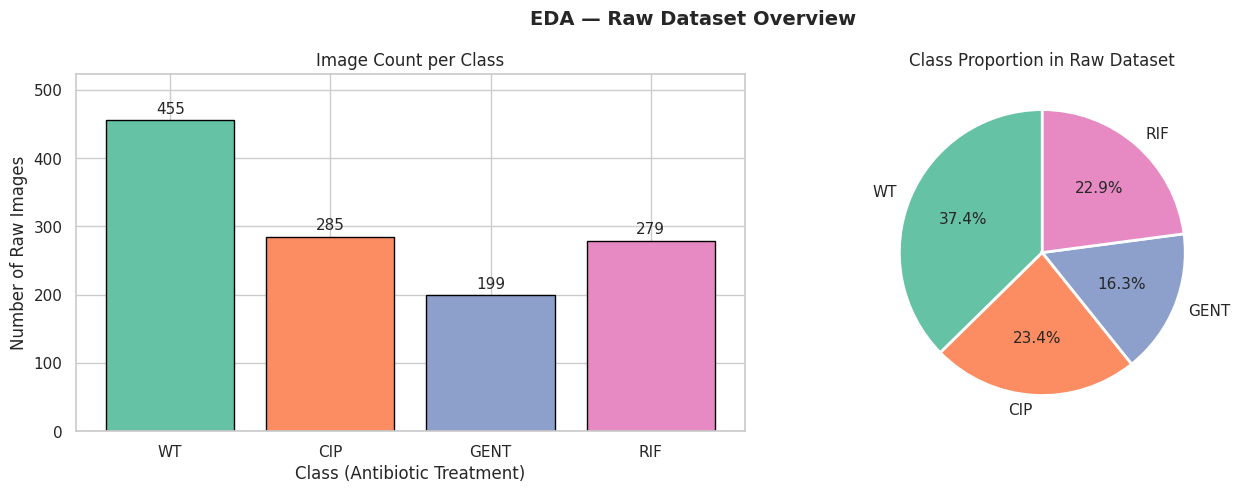

In [8]:
raw_counts = {}
for cls in CLASSES:
    cls_path = os.path.join(raw_parent_dir, cls)
    raw_counts[cls] = len([f for f in os.listdir(cls_path) if f.endswith('.tif')])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("EDA — Raw Dataset Overview", fontsize=14, fontweight='bold')

# Bar chart
bars = axes[0].bar(raw_counts.keys(), raw_counts.values(),
                   color=sns.color_palette("Set2", len(CLASSES)), edgecolor='black')
axes[0].bar_label(bars, fmt='%d', padding=3, fontsize=11)
axes[0].set_title("Image Count per Class")
axes[0].set_xlabel("Class (Antibiotic Treatment)")
axes[0].set_ylabel("Number of Raw Images")
axes[0].set_ylim(0, max(raw_counts.values()) * 1.15)

# Pie chart
axes[1].pie(
    raw_counts.values(),
    labels=raw_counts.keys(),
    autopct='%1.1f%%',
    colors=sns.color_palette("Set2", len(CLASSES)),
    startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
axes[1].set_title("Class Proportion in Raw Dataset")

plt.tight_layout()
plt.savefig("eda_01_raw_class_distribution.png", bbox_inches='tight')
plt.show()

#### **Sample Image per Class**

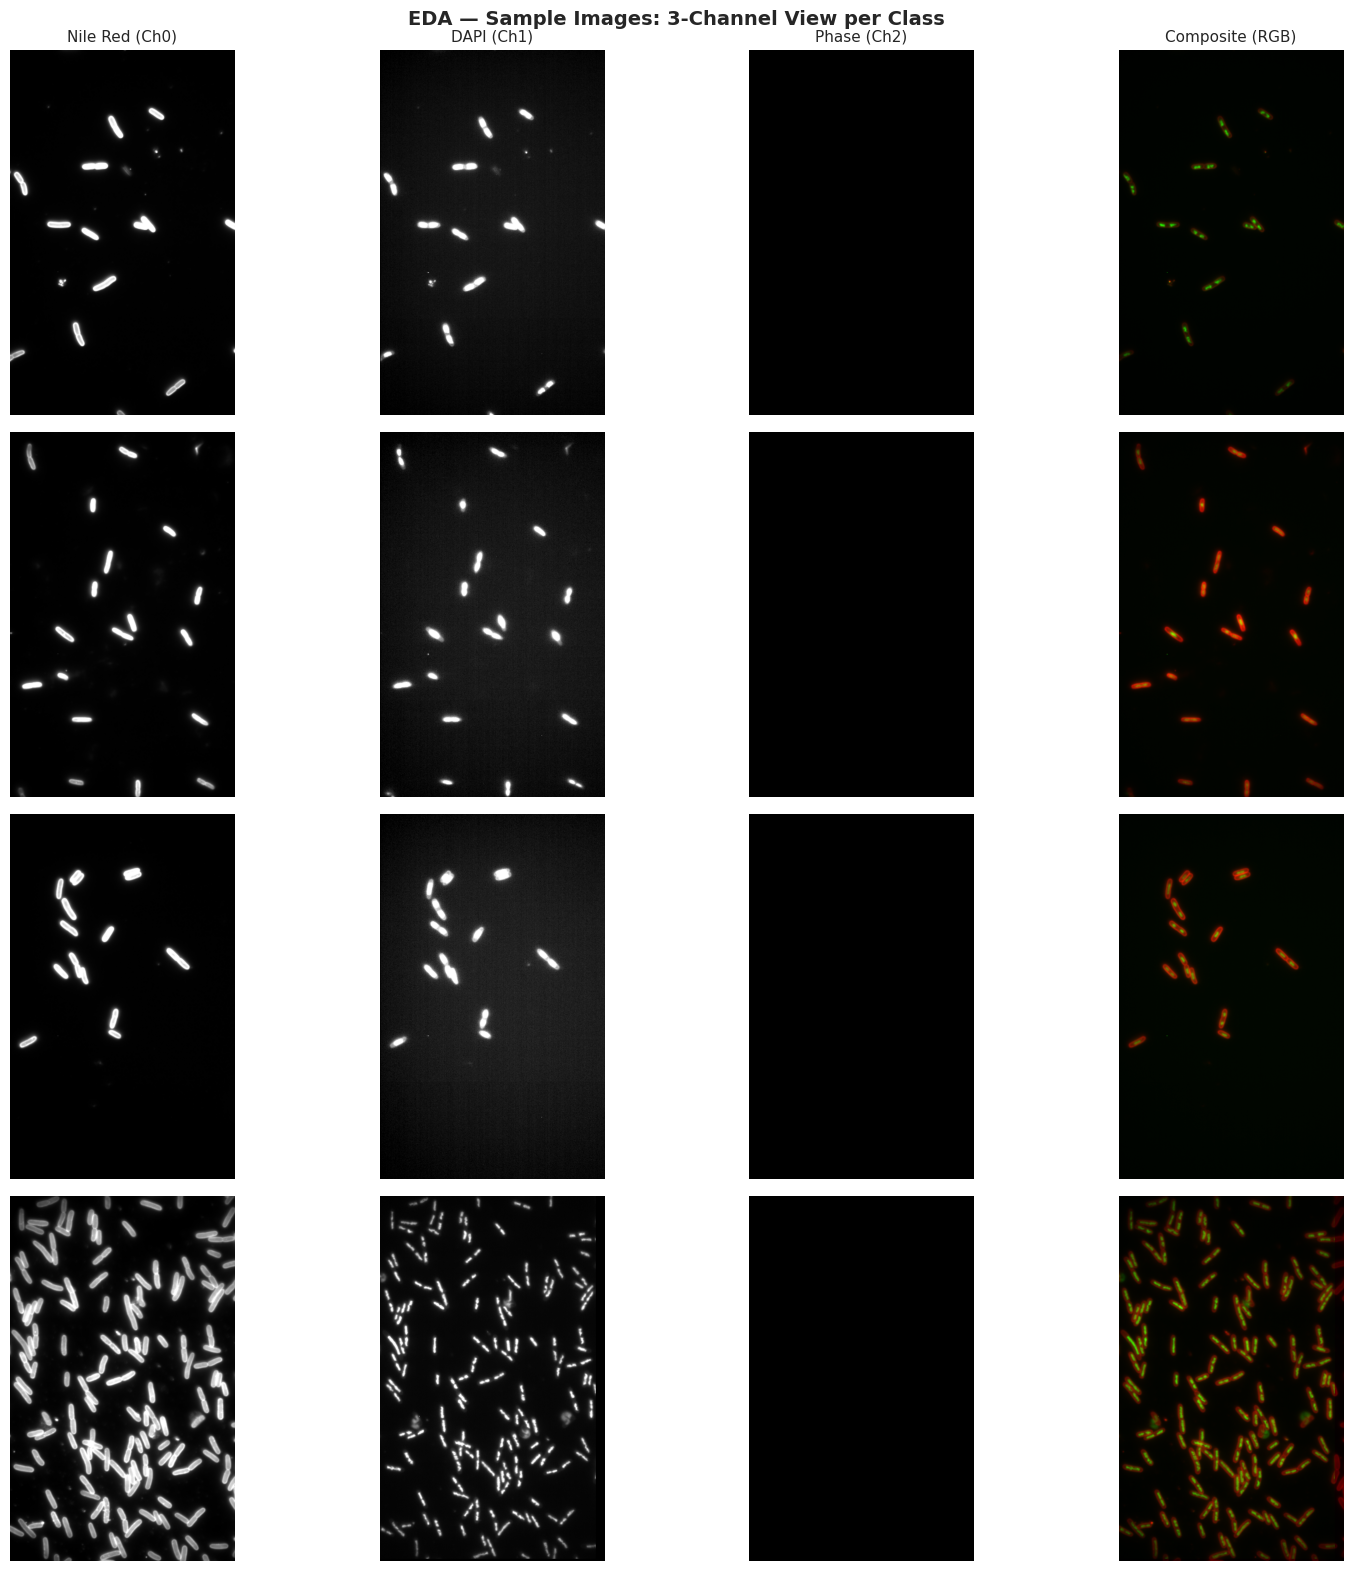

In [9]:
fig, axes = plt.subplots(nrows=len(CLASSES), ncols=4, figsize=(16, 4 * len(CLASSES)))
fig.suptitle("EDA — Sample Images: 3-Channel View per Class", fontsize=14, fontweight='bold')

channel_names = ['Nile Red (Ch0)', 'DAPI (Ch1)', 'Phase (Ch2)', 'Composite (RGB)']

for row, cls in enumerate(CLASSES):
    cls_path = os.path.join(raw_parent_dir, cls)
    tifs = [f for f in os.listdir(cls_path) if f.endswith('.tif')]
    img_path = os.path.join(cls_path, random.choice(tifs))
    img = tifffile.imread(img_path)  # shape: (3, H, W)

    for col in range(3):
        ch = img[col].astype(np.float32)
        p1, p99 = np.percentile(ch, (1, 99))
        ch = np.clip(ch, p1, p99)
        ch = (ch - p1) / (p99 - p1 + 1e-8)
        axes[row, col].imshow(ch, cmap='gray')
        axes[row, col].axis('off')
        if row == 0:
            axes[row, col].set_title(channel_names[col], fontsize=11)

    # Composite
    composite = np.transpose(img, (1, 2, 0)).astype(np.float32)
    composite = (composite - composite.min()) / (composite.max() - composite.min() + 1e-8)
    axes[row, 3].imshow(composite)
    axes[row, 3].axis('off')
    if row == 0:
        axes[row, 3].set_title(channel_names[3], fontsize=11)

    axes[row, 0].set_ylabel(cls, fontsize=12, fontweight='bold', labelpad=10)

plt.tight_layout()
plt.savefig("eda_02_sample_images_per_class.png", bbox_inches='tight')
plt.show()

#### **Pixel Intensity Distribution per Channel per Class**

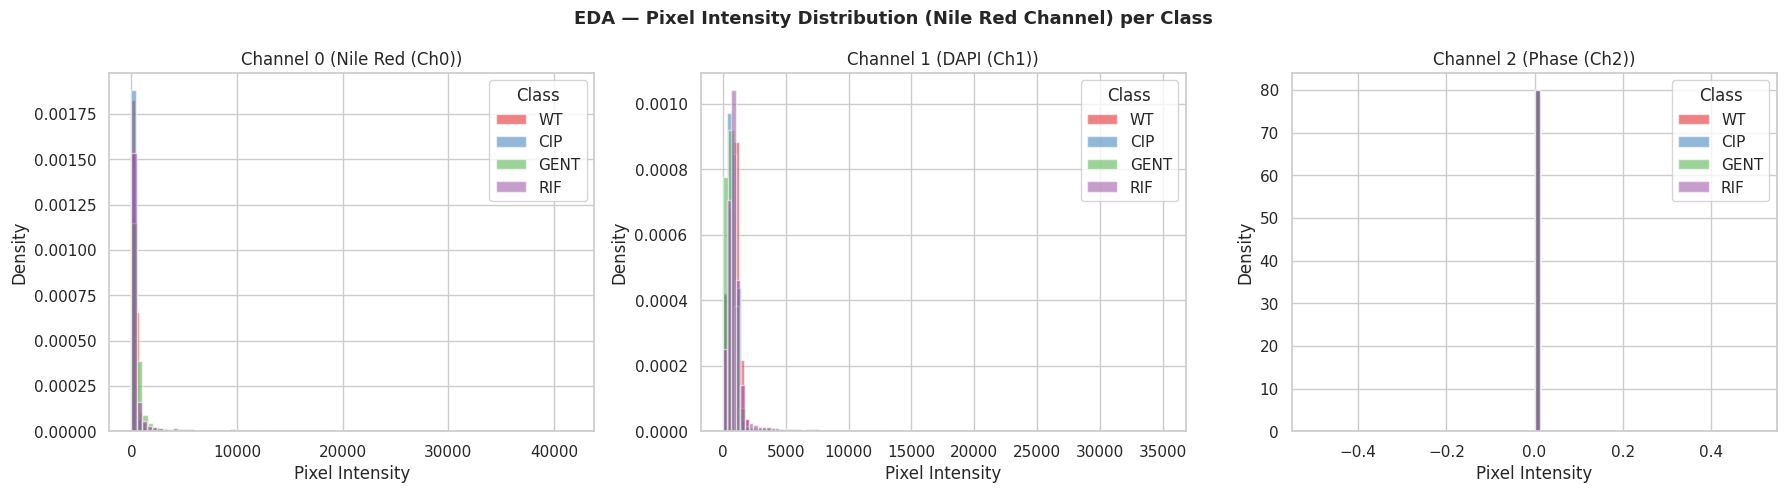

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("EDA — Pixel Intensity Distribution (Nile Red Channel) per Class",
             fontsize=13, fontweight='bold')

palette = sns.color_palette("Set1", len(CLASSES))

for cls_idx, cls in enumerate(CLASSES):
    cls_path = os.path.join(raw_parent_dir, cls)
    tifs = [f for f in os.listdir(cls_path) if f.endswith('.tif')]
    # Sample up to 10 images for speed
    sampled = random.sample(tifs, min(10, len(tifs)))

    all_pixels = []
    for fn in sampled:
        img = tifffile.imread(os.path.join(cls_path, fn))
        for ch_idx in range(3):
            ch = img[ch_idx].flatten().astype(np.float32)
            # store a sample of pixels
            if cls_idx == 0:
                all_pixels = ch[:5000]
            else:
                all_pixels = np.concatenate([all_pixels, ch[:5000]])

    # Per-channel histogram (channel 0: Nile Red)
    for ch_idx in range(3):
        ch_pixels = []
        for fn in sampled:
            img = tifffile.imread(os.path.join(cls_path, fn))
            ch = img[ch_idx].flatten().astype(np.float32)
            ch_pixels.extend(ch[:3000].tolist())

        axes[ch_idx].hist(
            ch_pixels, bins=80, alpha=0.55,
            label=cls, color=palette[cls_idx], density=True
        )
        axes[ch_idx].set_title(f"Channel {ch_idx} ({channel_names[ch_idx]})")
        axes[ch_idx].set_xlabel("Pixel Intensity")
        axes[ch_idx].set_ylabel("Density")

for ax in axes:
    ax.legend(title="Class")

plt.tight_layout()
plt.savefig("eda_03_pixel_intensity_distribution.png", bbox_inches='tight')
plt.show()

#### **Morphological Feature EDA (Cell Area & Eccentricity)**

  Extracted morphological features from 1100 cells.


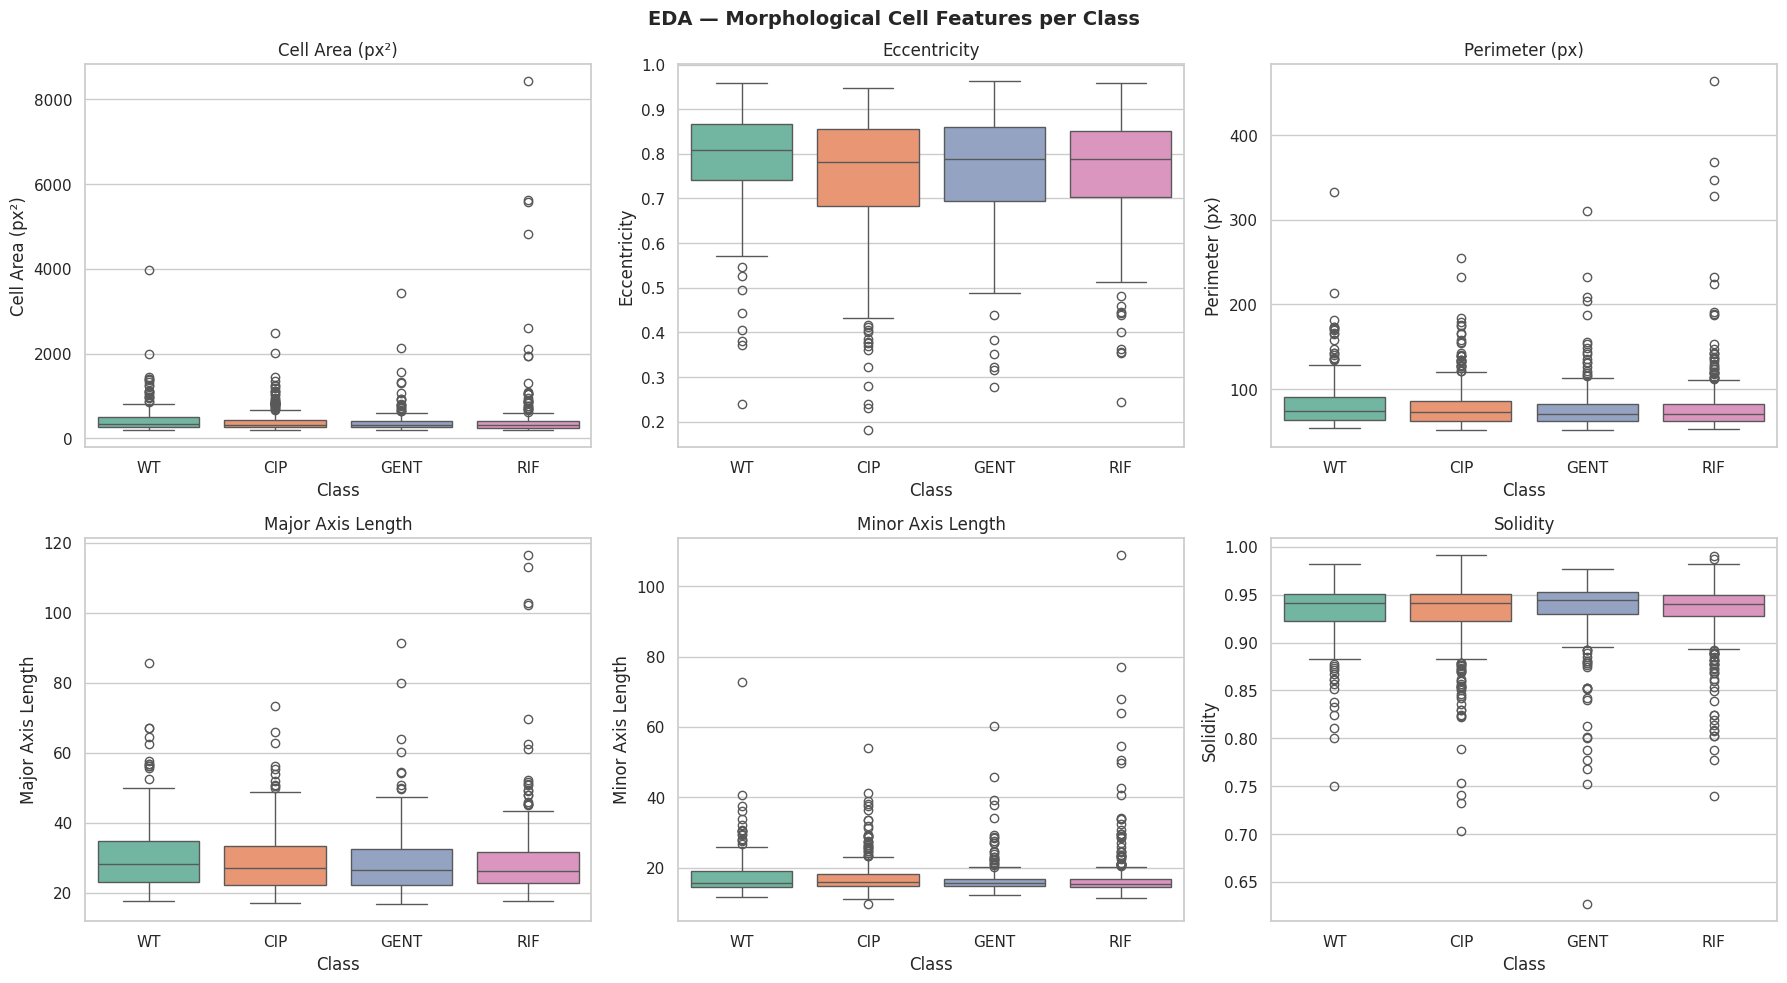

In [11]:
CLAHE_eda = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def quick_segment(nile_img):
    nile = cv2.normalize(nile_img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    enhanced = CLAHE_eda.apply(nile)
    blur = cv2.GaussianBlur(enhanced, (3, 3), 0)
    adaptive = cv2.adaptiveThreshold(blur, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 51, 5)
    binary = adaptive.astype(bool)
    binary = morphology.remove_small_objects(binary, min_size=100)
    binary = morphology.remove_small_holes(binary, area_threshold=100)
    binary = clear_border(binary)
    if np.sum(binary) == 0:
        return None
    distance = ndi.distance_transform_edt(binary)
    local_max = peak_local_max(distance, min_distance=10, labels=binary)
    markers = np.zeros_like(distance, dtype=np.int32)
    markers[tuple(local_max.T)] = np.arange(1, len(local_max) + 1)
    labels = watershed(-distance, markers, mask=binary)
    return labels

morph_data = []
for cls in CLASSES:
    cls_path = os.path.join(raw_parent_dir, cls)
    tifs = [f for f in os.listdir(cls_path) if f.endswith('.tif')]
    for fn in random.sample(tifs, min(5, len(tifs))):
        img = tifffile.imread(os.path.join(cls_path, fn))
        labels = quick_segment(img[0])
        if labels is None:
            continue
        for region in measure.regionprops(labels):
            if region.area >= 200:
                morph_data.append({
                    'class': cls,
                    'area': region.area,
                    'eccentricity': region.eccentricity,
                    'perimeter': region.perimeter,
                    'major_axis': region.major_axis_length,
                    'minor_axis': region.minor_axis_length,
                    'solidity': region.solidity
                })

morph_df = pd.DataFrame(morph_data)
print(f"  Extracted morphological features from {len(morph_df)} cells.")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("EDA — Morphological Cell Features per Class", fontsize=14, fontweight='bold')

features = ['area', 'eccentricity', 'perimeter', 'major_axis', 'minor_axis', 'solidity']
feat_labels = ['Cell Area (px²)', 'Eccentricity', 'Perimeter (px)',
               'Major Axis Length', 'Minor Axis Length', 'Solidity']

for ax, feat, lbl in zip(axes.flat, features, feat_labels):
    sns.boxplot(data=morph_df, x='class', y=feat, palette='Set2', ax=ax, order=CLASSES)
    ax.set_title(lbl)
    ax.set_xlabel("Class")
    ax.set_ylabel(lbl)

plt.tight_layout()
plt.savefig("eda_04_morphological_features.png", bbox_inches='tight')
plt.show()

#### **Pairplot of Morphological Features**

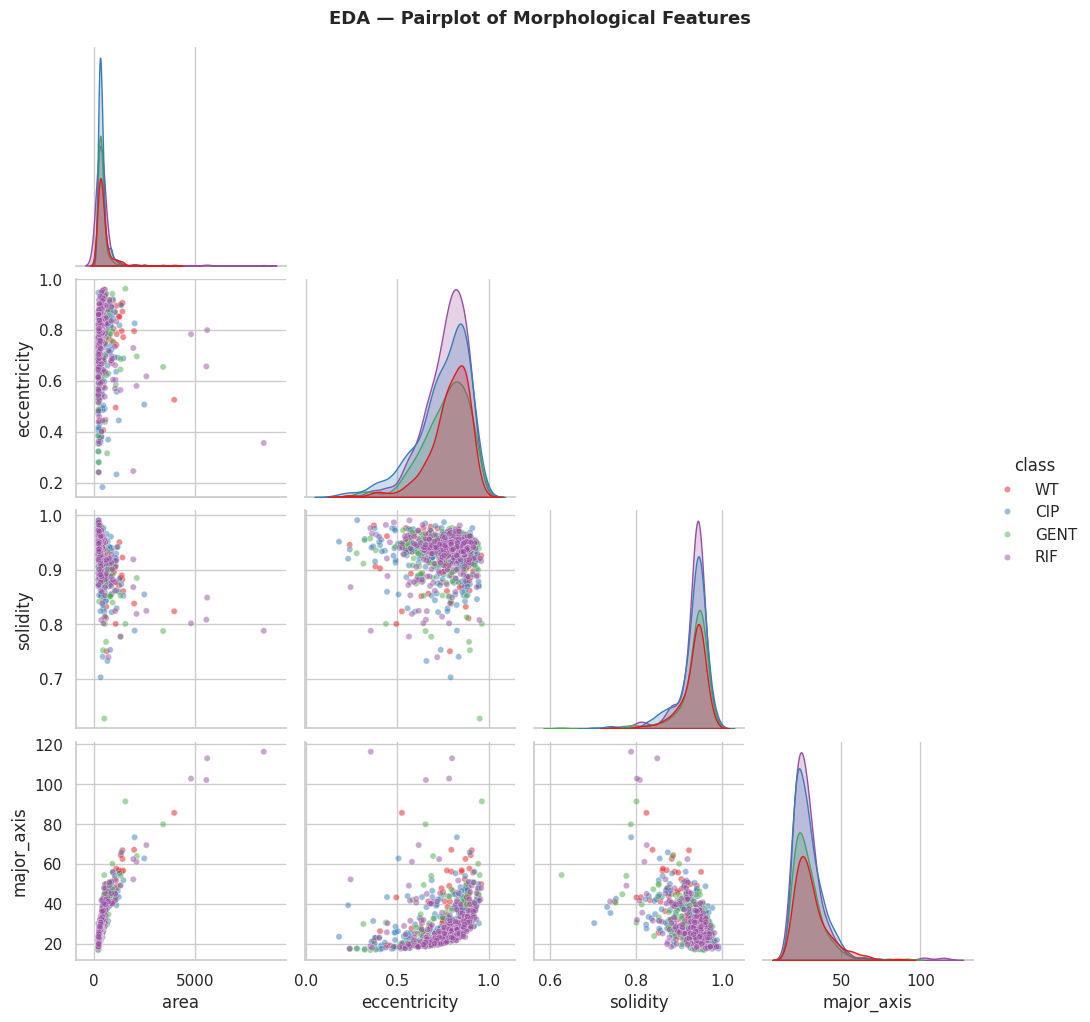

In [12]:
pair_cols = ['area', 'eccentricity', 'solidity', 'major_axis', 'class']
pair_subset = morph_df[pair_cols].copy()
g = sns.pairplot(pair_subset, hue='class', palette='Set1',
                 plot_kws={'alpha': 0.5, 's': 20},
                 diag_kind='kde', corner=True)
g.fig.suptitle("EDA — Pairplot of Morphological Features", y=1.02,
               fontsize=13, fontweight='bold')
plt.savefig("eda_05_morphological_pairplot.png", bbox_inches='tight')
plt.show()

#### **Correlation Heatmap**

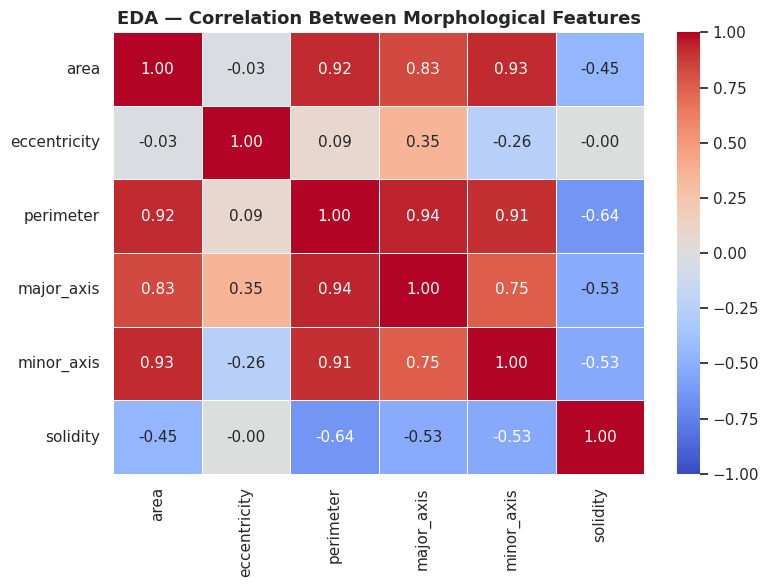

In [13]:
corr_cols = ['area', 'eccentricity', 'perimeter', 'major_axis', 'minor_axis', 'solidity']
corr_matrix = morph_df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, ax=ax, linewidths=0.5)
ax.set_title("EDA — Correlation Between Morphological Features", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("eda_06_feature_correlation_heatmap.png", bbox_inches='tight')
plt.show()

#### **Violin Plot -> Cell count per image per class**

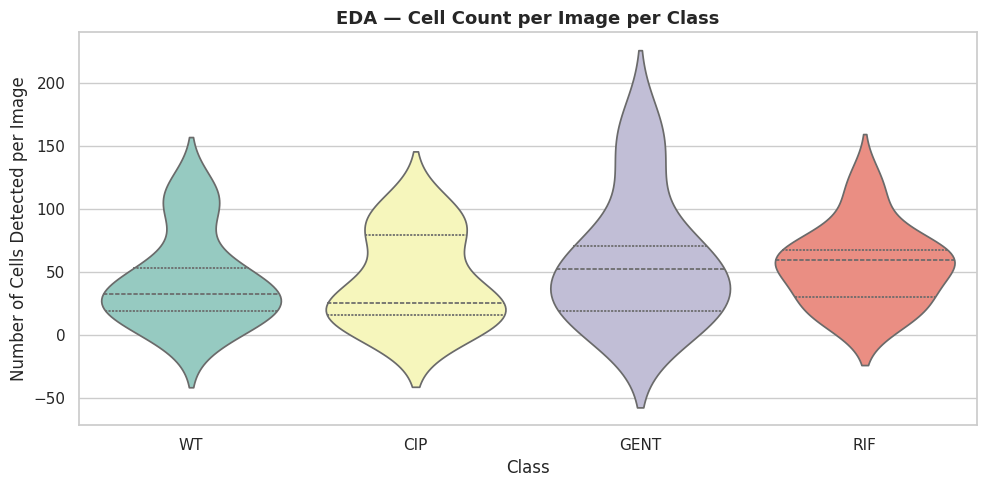

In [14]:
cell_count_data = []
for cls in CLASSES:
    cls_path = os.path.join(raw_parent_dir, cls)
    tifs = [f for f in os.listdir(cls_path) if f.endswith('.tif')]
    for fn in random.sample(tifs, min(15, len(tifs))):
        img = tifffile.imread(os.path.join(cls_path, fn))
        labels = quick_segment(img[0])
        if labels is None:
            count = 0
        else:
            count = len([r for r in measure.regionprops(labels) if r.area >= 200])
        cell_count_data.append({'class': cls, 'cell_count': count})

cell_count_df = pd.DataFrame(cell_count_data)

fig, ax = plt.subplots(figsize=(10, 5))
sns.violinplot(data=cell_count_df, x='class', y='cell_count',
               palette='Set3', order=CLASSES, inner='quartile', ax=ax)
ax.set_title("EDA — Cell Count per Image per Class", fontsize=13, fontweight='bold')
ax.set_xlabel("Class")
ax.set_ylabel("Number of Cells Detected per Image")
plt.tight_layout()
plt.savefig("eda_07_cell_count_violin.png", bbox_inches='tight')
plt.show()

## **Data Splitting**

In [15]:
source_dir = raw_parent_dir
target_dir = "intermediate"
SPLITS = ["train", "val", "test"]

for split in SPLITS:
    for cls in CLASSES:
        os.makedirs(os.path.join(target_dir, split, cls), exist_ok=True)

train_ratio, val_ratio, test_ratio = 0.70, 0.15, 0.15

In [16]:
split_summary = {}
for cls in CLASSES:
    cls_path = os.path.join(source_dir, cls)
    images = [f for f in os.listdir(cls_path) if f.endswith('.tif')]
    random.shuffle(images)

    total = len(images)
    train_end = int(train_ratio * total)
    val_end   = train_end + int(val_ratio * total)

    sets = {
        'train': images[:train_end],
        'val':   images[train_end:val_end],
        'test':  images[val_end:]
    }
    split_summary[cls] = {s: len(v) for s, v in sets.items()}

    for split_name, imgs in sets.items():
        for img_file in imgs:
            shutil.copy2(
                os.path.join(cls_path, img_file),
                os.path.join(target_dir, split_name, cls, img_file)
            )

In [17]:
print("\nSplit Summary:")
split_df = pd.DataFrame(split_summary).T
split_df.columns.name = 'Split'
print(split_df)


Split Summary:
Split  train  val  test
WT       318   68    69
CIP      199   42    44
GENT     139   29    31
RIF      195   41    43


## **Cell Segmentation**

In [18]:
BASE_PATH   = "intermediate"
DST_PATH    = "segmented images"
NILE_CH     = 0
MIN_AREA    = 200
RESIZE      = 128
CLAHE_seg   = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

In [19]:
def pad_to_square(img):
    h, w, c = img.shape
    size = max(h, w)
    padded = np.zeros((size, size, c), dtype=img.dtype)
    y_off = (size - h) // 2
    x_off = (size - w) // 2
    padded[y_off:y_off+h, x_off:x_off+w] = img
    return padded

In [20]:
def segment_cells(nile_img):
    nile     = cv2.normalize(nile_img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    enhanced = CLAHE_seg.apply(nile)
    blur     = cv2.GaussianBlur(enhanced, (3, 3), 0)
    adaptive = cv2.adaptiveThreshold(
        blur, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 51, 5
    )
    binary = adaptive.astype(bool)
    binary = morphology.remove_small_objects(binary, min_size=100)
    binary = morphology.remove_small_holes(binary, area_threshold=100)
    binary = clear_border(binary)
    if np.sum(binary) == 0:
        return None
    distance  = ndi.distance_transform_edt(binary)
    local_max = peak_local_max(distance, min_distance=10, labels=binary)
    markers   = np.zeros_like(distance, dtype=np.int32)
    markers[tuple(local_max.T)] = np.arange(1, len(local_max) + 1)
    labels = watershed(-distance, markers, mask=binary)
    return labels

In [21]:
segmentation_summary = {s: {c: 0 for c in CLASSES} for s in SPLITS}

for split in SPLITS:
    print(f"\n  Processing {split} split...")
    input_split  = os.path.join(BASE_PATH, split)
    output_split = os.path.join(DST_PATH, f"{split}_segmented")

    for cls in CLASSES:
        input_cls  = os.path.join(input_split, cls)
        output_cls = os.path.join(output_split, cls)
        os.makedirs(output_cls, exist_ok=True)

        images = [f for f in os.listdir(input_cls) if f.endswith('.tif')]
        cell_id = 0

        for img_name in images:
            img_path = os.path.join(input_cls, img_name)
            try:
                img = tifffile.imread(img_path)
            except Exception:
                continue

            labels = segment_cells(img[NILE_CH])
            if labels is None:
                continue

            full_img = np.transpose(img, (1, 2, 0))

            for region in measure.regionprops(labels):
                if region.area < MIN_AREA:
                    continue
                if region.eccentricity < 0.6:
                    continue

                minr, minc, maxr, maxc = region.bbox
                crop = full_img[minr:maxr, minc:maxc].copy()
                mask = (labels[minr:maxr, minc:maxc] == region.label)
                crop[~mask] = 0

                crop = pad_to_square(crop)
                crop = cv2.resize(crop, (RESIZE, RESIZE))

                save_name = f"{cls}_{img_name[:-4]}_cell_{cell_id}.png"
                cv2.imwrite(
                    os.path.join(output_cls, save_name),
                    cv2.cvtColor(crop, cv2.COLOR_RGB2BGR)
                )
                cell_id += 1

        segmentation_summary[split][cls] = cell_id
        print(f"    {cls}: {cell_id} cells saved")


  Processing train split...
    WT: 11301 cells saved
    CIP: 6921 cells saved
    GENT: 6130 cells saved
    RIF: 8510 cells saved

  Processing val split...
    WT: 2655 cells saved
    CIP: 1086 cells saved
    GENT: 1144 cells saved
    RIF: 2054 cells saved

  Processing test split...
    WT: 3060 cells saved
    CIP: 1740 cells saved
    GENT: 1504 cells saved
    RIF: 1792 cells saved


In [22]:
# Segmented cell count bar chart
seg_df = pd.DataFrame(segmentation_summary).T
print("\nSegmented Cell Counts:")
print(seg_df)


Segmented Cell Counts:
          WT   CIP  GENT   RIF
train  11301  6921  6130  8510
val     2655  1086  1144  2054
test    3060  1740  1504  1792


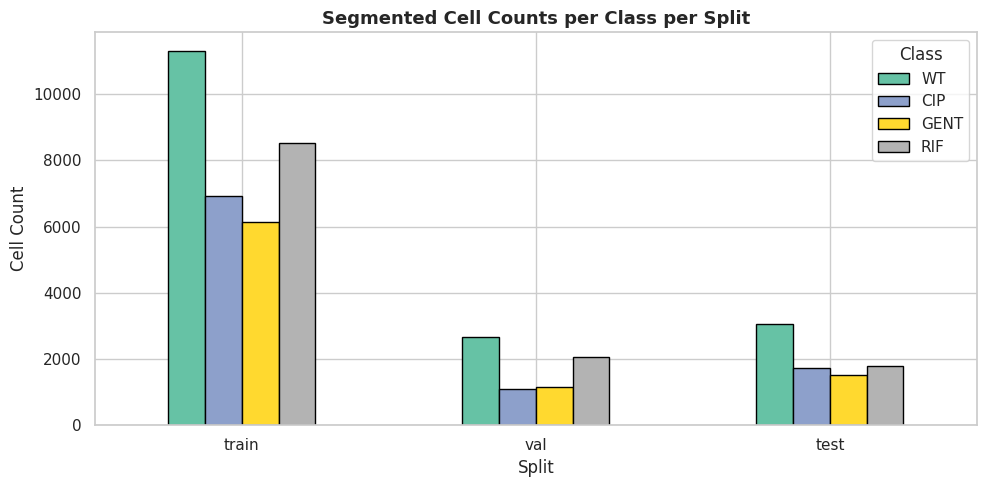

In [23]:
fig, ax = plt.subplots(figsize=(10, 5))
seg_df.plot(kind='bar', ax=ax, colormap='Set2', edgecolor='black')
ax.set_title("Segmented Cell Counts per Class per Split", fontsize=13, fontweight='bold')
ax.set_xlabel("Split")
ax.set_ylabel("Cell Count")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title='Class')
plt.tight_layout()
plt.savefig("segmentation_cell_counts.png", bbox_inches='tight')
plt.show()

## **Data Loaders & Augmentation**

In [24]:
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 64

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    vertical_flip=True,
    zoom_range=0.15,
    shear_range=0.1,
    brightness_range=[0.85, 1.15],
    fill_mode='reflect'
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    'segmented images/train_segmented',
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_gen = val_test_datagen.flow_from_directory(
    'segmented images/val_segmented',
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_gen = val_test_datagen.flow_from_directory(
    'segmented images/test_segmented',
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 32862 images belonging to 4 classes.
Found 6939 images belonging to 4 classes.
Found 8096 images belonging to 4 classes.


In [25]:
CLASS_NAMES = list(train_gen.class_indices.keys())
NUM_CLASSES = train_gen.num_classes
print(f"\nClasses : {CLASS_NAMES}")
print(f"Train   : {train_gen.samples} images")
print(f"Val     : {val_gen.samples} images")
print(f"Test    : {test_gen.samples} images")


Classes : ['CIP', 'GENT', 'RIF', 'WT']
Train   : 32862 images
Val     : 6939 images
Test    : 8096 images


In [26]:
# Class weights for imbalance
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_gen.classes),
    y=train_gen.classes
)
class_weights_dict = dict(enumerate(class_weights))
print(f"\nClass Weights: {class_weights_dict}")


Class Weights: {0: np.float64(1.1870394451668833), 1: np.float64(1.3402120717781403), 2: np.float64(0.9653936545240893), 3: np.float64(0.7269710645075657)}


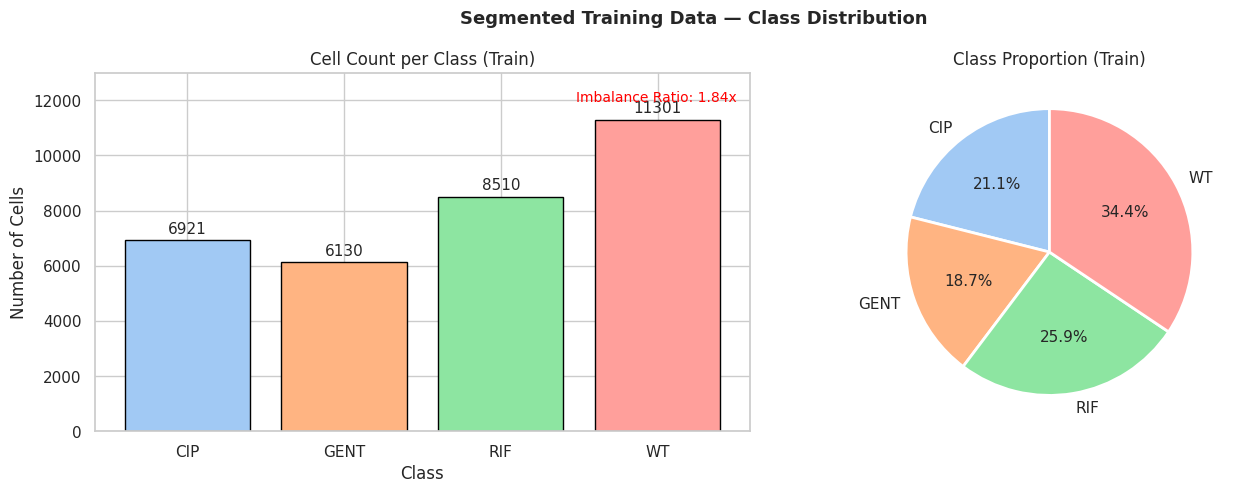

In [27]:
seg_train_counts = {cls: len(os.listdir(os.path.join('segmented images/train_segmented', cls)))
                    for cls in CLASS_NAMES}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Segmented Training Data — Class Distribution", fontsize=13, fontweight='bold')

bars = axes[0].bar(seg_train_counts.keys(), seg_train_counts.values(),
                   color=sns.color_palette("pastel", NUM_CLASSES), edgecolor='black')
axes[0].bar_label(bars, fmt='%d', padding=3)
axes[0].set_title("Cell Count per Class (Train)")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of Cells")

counts_arr = np.array(list(seg_train_counts.values()))
imbalance_ratio = counts_arr.max() / counts_arr.min()
axes[0].set_ylim(0, counts_arr.max() * 1.15)
axes[0].text(0.98, 0.95, f"Imbalance Ratio: {imbalance_ratio:.2f}x",
             transform=axes[0].transAxes, ha='right', va='top',
             fontsize=10, color='red')

axes[1].pie(
    seg_train_counts.values(),
    labels=seg_train_counts.keys(),
    autopct='%1.1f%%',
    colors=sns.color_palette("pastel", NUM_CLASSES),
    startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
axes[1].set_title("Class Proportion (Train)")

plt.tight_layout()
plt.savefig("segmented_train_distribution.png", bbox_inches='tight')
plt.show()

## **Model Definitions**

In [28]:
EPOCHS = 25

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=8,
                            restore_best_weights=True, verbose=1)
reduce_lr  = ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                patience=4, min_lr=1e-7, verbose=1)
CALLBACKS  = [early_stop, reduce_lr]

#### **Custom CNN**

In [29]:
def build_cnn(num_classes, input_shape=(128, 128, 3)):
    model = Sequential([
        Input(shape=input_shape),
        # Block 1
        Conv2D(32, 3, activation='relu', padding='same'),
        BatchNormalization(),
        Conv2D(32, 3, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D(2),
        Dropout(0.25),
        # Block 2
        Conv2D(64, 3, activation='relu', padding='same'),
        BatchNormalization(),
        Conv2D(64, 3, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D(2),
        Dropout(0.25),
        # Block 3
        Conv2D(128, 3, activation='relu', padding='same'),
        BatchNormalization(),
        Conv2D(128, 3, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D(2),
        Dropout(0.30),
        # Block 4
        Conv2D(256, 3, activation='relu', padding='same'),
        BatchNormalization(),
        Conv2D(256, 3, activation='relu', padding='same'),
        BatchNormalization(),
        MaxPooling2D(2),
        Dropout(0.40),
        # Classifier head
        GlobalAveragePooling2D(),
        Dense(512, activation='relu'),
        BatchNormalization(),
        Dropout(0.50),
        Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.30),
        Dense(num_classes, activation='softmax')
    ], name='CustomCNN')
    return model

In [30]:
cnn_model = build_cnn(NUM_CLASSES)
cnn_model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy', 'precision', 'recall', F1Score(average='macro')]
)

# cnn_model.summary()

#### **DenseNet169**

In [31]:
def build_densenet(num_classes, input_shape=(128, 128, 3)):
    base = DenseNet169(include_top=False, weights='imagenet', input_shape=input_shape)
    # Fine-tune top 30 layers
    for layer in base.layers[:-30]:
        layer.trainable = False
    for layer in base.layers[-30:]:
        layer.trainable = True

    x = GlobalAveragePooling2D()(base.output)
    x = Dense(512, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.5)(x)
    x = Dense(256, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.3)(x)
    out = Dense(num_classes, activation='softmax')(x)
    return Model(inputs=base.input, outputs=out, name='DenseNet169_FT')

In [32]:
densenet_model = build_densenet(NUM_CLASSES)
densenet_model.compile(
    optimizer=Adam(learning_rate=5e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy', 'precision', 'recall', F1Score(average='macro')]
)
# densenet_model.summary()

51877672/51877672 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


#### **EfficientNetB0**

In [33]:
def build_efficientnet(num_classes, input_shape=(128, 128, 3)):
    base = EfficientNetB0(include_top=False, weights='imagenet', input_shape=input_shape)
    for layer in base.layers[:-20]:
        layer.trainable = False
    for layer in base.layers[-20:]:
        layer.trainable = True

    x = GlobalAveragePooling2D()(base.output)
    x = Dense(256, activation='relu')(x)
    x = BatchNormalization()(x)
    x = Dropout(0.5)(x)
    out = Dense(num_classes, activation='softmax')(x)
    return Model(inputs=base.input, outputs=out, name='EfficientNetB0_FT')

In [34]:
efficientnet_model = build_efficientnet(NUM_CLASSES)
efficientnet_model.compile(
    optimizer=Adam(learning_rate=5e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy', 'precision', 'recall', F1Score(average='macro')]
)
# efficientnet_model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


#### **Vision Transformers**

In [35]:
PATCH_SIZE     = 16
NUM_PATCHES    = (IMAGE_SIZE[0] // PATCH_SIZE) ** 2
PROJ_DIM       = 128
NUM_HEADS      = 8
TRANSFORMER_L  = 6
MLP_UNITS      = [512, 256]

In [36]:
class Patches(layers.Layer):
    def __init__(self, patch_size, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, images):
        patches = tf.image.extract_patches(
            images=images,
            sizes=[1, self.patch_size, self.patch_size, 1],
            strides=[1, self.patch_size, self.patch_size, 1],
            rates=[1, 1, 1, 1],
            padding="VALID"
        )
        patch_dims = patches.shape[-1]
        patches = tf.reshape(patches, [tf.shape(images)[0], -1, patch_dims])
        return patches

In [37]:
class PatchEncoder(layers.Layer):
    def __init__(self, num_patches, projection_dim, **kwargs):
        super().__init__(**kwargs)
        self.num_patches   = num_patches
        self.projection    = layers.Dense(projection_dim)
        self.pos_embedding = layers.Embedding(num_patches, projection_dim)

    def call(self, patch):
        positions = tf.range(0, self.num_patches, delta=1)
        return self.projection(patch) + self.pos_embedding(positions)

In [38]:
def build_vit(num_classes, input_shape=(128, 128, 3)):
    inputs = layers.Input(shape=input_shape)
    patches = Patches(PATCH_SIZE)(inputs)
    encoded = PatchEncoder(NUM_PATCHES, PROJ_DIM)(patches)

    for _ in range(TRANSFORMER_L):
        x1  = LayerNormalization(epsilon=1e-6)(encoded)
        att = MultiHeadAttention(num_heads=NUM_HEADS, key_dim=PROJ_DIM, dropout=0.1)(x1, x1)
        x2  = Add()([att, encoded])
        x3  = LayerNormalization(epsilon=1e-6)(x2)
        x3  = layers.Dense(PROJ_DIM * 2, activation='gelu')(x3)
        x3  = layers.Dropout(0.1)(x3)
        x3  = layers.Dense(PROJ_DIM, activation='gelu')(x3)
        x3  = layers.Dropout(0.1)(x3)
        encoded = Add()([x3, x2])

    rep = LayerNormalization(epsilon=1e-6)(encoded)
    rep = layers.GlobalAveragePooling1D()(rep)
    rep = layers.Dropout(0.4)(rep)
    for units in MLP_UNITS:
        rep = layers.Dense(units, activation='gelu')(rep)
        rep = layers.Dropout(0.3)(rep)
    out = layers.Dense(num_classes, activation='softmax')(rep)
    return Model(inputs=inputs, outputs=out, name='ViT')

In [39]:
vit_model = build_vit(NUM_CLASSES)
vit_model.compile(
    optimizer=optimizers.AdamW(learning_rate=1e-4, weight_decay=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy', 'precision', 'recall', F1Score(average='macro')]
)
# vit_model.summary()

## **Model Trainings**

#### **CNN Training**

In [40]:
cnn_history = cnn_model.fit(
    train_gen, epochs=EPOCHS,
    validation_data=val_gen,
    class_weight=class_weights_dict,
    callbacks=CALLBACKS, verbose=1
)

Epoch 1/25
514/514 ━━━━━━━━━━━━━━━━━━━━ 291s 506ms/step - accuracy: 0.3860 - f1_score: 0.3840 - loss: 1.5826 - precision: 0.4117 - recall: 0.2901 - val_accuracy: 0.2287 - val_f1_score: 0.1504 - val_loss: 3.4184 - val_precision: 0.2286 - val_recall: 0.2281 - learning_rate: 1.0000e-04
Epoch 2/25
514/514 ━━━━━━━━━━━━━━━━━━━━ 230s 447ms/step - accuracy: 0.4440 - f1_score: 0.4421 - loss: 1.3537 - precision: 0.4814 - recall: 0.3371 - val_accuracy: 0.3764 - val_f1_score: 0.1991 - val_loss: 2.5019 - val_precision: 0.3791 - val_recall: 0.3532 - learning_rate: 1.0000e-04
Epoch 3/25
514/514 ━━━━━━━━━━━━━━━━━━━━ 231s 449ms/step - accuracy: 0.4808 - f1_score: 0.4793 - loss: 1.2396 - precision: 0.5195 - recall: 0.3667 - val_accuracy: 0.4388 - val_f1_score: 0.3055 - val_loss: 1.8574 - val_precision: 0.4497 - val_recall: 0.4048 - learning_rate: 1.0000e-04
Epoch 4/25
514/514 ━━━━━━━━━━━━━━━━━━━━ 231s 449ms/step - accuracy: 0.5032 - f1_score: 0.5014 - loss: 1.1794 - precision: 0.5483 - recall: 0.3942 - 

#### **DenseNet169 Training**

In [41]:
densenet_history = densenet_model.fit(
    train_gen, epochs=EPOCHS,
    validation_data=val_gen,
    class_weight=class_weights_dict,
    callbacks=CALLBACKS, verbose=1
)

Epoch 1/25
514/514 ━━━━━━━━━━━━━━━━━━━━ 353s 576ms/step - accuracy: 0.4313 - f1_score: 0.4244 - loss: 1.5203 - precision: 0.4690 - recall: 0.3555 - val_accuracy: 0.6324 - val_f1_score: 0.6090 - val_loss: 0.9304 - val_precision: 0.6988 - val_recall: 0.5613 - learning_rate: 5.0000e-05
Epoch 2/25
514/514 ━━━━━━━━━━━━━━━━━━━━ 230s 447ms/step - accuracy: 0.5697 - f1_score: 0.5570 - loss: 1.1577 - precision: 0.6147 - recall: 0.5078 - val_accuracy: 0.6907 - val_f1_score: 0.6597 - val_loss: 0.8184 - val_precision: 0.7363 - val_recall: 0.6410 - learning_rate: 5.0000e-05
Epoch 3/25
514/514 ━━━━━━━━━━━━━━━━━━━━ 228s 443ms/step - accuracy: 0.6146 - f1_score: 0.6026 - loss: 1.0339 - precision: 0.6597 - recall: 0.5582 - val_accuracy: 0.7102 - val_f1_score: 0.6896 - val_loss: 0.7802 - val_precision: 0.7587 - val_recall: 0.6644 - learning_rate: 5.0000e-05
Epoch 4/25
514/514 ━━━━━━━━━━━━━━━━━━━━ 0s 415ms/step - accuracy: 0.6430 - f1_score: 0.6315 - loss: 0.9653 - precision: 0.6847 - recall: 0.5859
Epoc

#### **EfficientNetB0 Training**

In [42]:
efficientnet_history = efficientnet_model.fit(
    train_gen, epochs=EPOCHS,
    validation_data=val_gen,
    class_weight=class_weights_dict,
    callbacks=CALLBACKS, verbose=1
)

Epoch 1/25
514/514 ━━━━━━━━━━━━━━━━━━━━ 291s 493ms/step - accuracy: 0.2536 - f1_score: 0.2501 - loss: 1.9147 - precision: 0.2536 - recall: 0.1250 - val_accuracy: 0.1565 - val_f1_score: 0.0677 - val_loss: 1.4204 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 5.0000e-05
Epoch 2/25
514/514 ━━━━━━━━━━━━━━━━━━━━ 211s 411ms/step - accuracy: 0.2545 - f1_score: 0.2503 - loss: 1.8079 - precision: 0.2530 - recall: 0.0944 - val_accuracy: 0.3244 - val_f1_score: 0.2000 - val_loss: 1.3708 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 5.0000e-05
Epoch 3/25
514/514 ━━━━━━━━━━━━━━━━━━━━ 209s 406ms/step - accuracy: 0.2558 - f1_score: 0.2524 - loss: 1.7258 - precision: 0.2503 - recall: 0.0729 - val_accuracy: 0.3280 - val_f1_score: 0.1852 - val_loss: 1.3700 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 5.0000e-05
Epoch 4/25
514/514 ━━━━━━━━━━━━━━━━━━━━ 0s 383ms/step - accuracy: 0.2481 - f1_score: 0.2444 - loss: 1.6813 - precision: 0.24

#### **Vision Transformers Training**

In [43]:
vit_history = vit_model.fit(
    train_gen, epochs=EPOCHS,
    validation_data=val_gen,
    class_weight=class_weights_dict,
    callbacks=CALLBACKS, verbose=1
)

Epoch 1/25
514/514 ━━━━━━━━━━━━━━━━━━━━ 296s 493ms/step - accuracy: 0.3802 - f1_score: 0.3766 - loss: 1.2772 - precision: 0.4976 - recall: 0.0938 - val_accuracy: 0.4875 - val_f1_score: 0.4709 - val_loss: 1.1331 - val_precision: 0.5527 - val_recall: 0.2245 - learning_rate: 1.0000e-04
Epoch 2/25
514/514 ━━━━━━━━━━━━━━━━━━━━ 226s 440ms/step - accuracy: 0.4770 - f1_score: 0.4713 - loss: 1.1579 - precision: 0.5557 - recall: 0.2400 - val_accuracy: 0.5194 - val_f1_score: 0.5037 - val_loss: 1.0911 - val_precision: 0.5948 - val_recall: 0.2418 - learning_rate: 1.0000e-04
Epoch 3/25
514/514 ━━━━━━━━━━━━━━━━━━━━ 229s 445ms/step - accuracy: 0.5106 - f1_score: 0.5058 - loss: 1.0988 - precision: 0.5891 - recall: 0.3063 - val_accuracy: 0.5527 - val_f1_score: 0.5382 - val_loss: 1.0150 - val_precision: 0.6178 - val_recall: 0.4210 - learning_rate: 1.0000e-04
Epoch 4/25
514/514 ━━━━━━━━━━━━━━━━━━━━ 0s 418ms/step - accuracy: 0.5270 - f1_score: 0.5247 - loss: 1.0620 - precision: 0.6061 - recall: 0.3455
Epoc

## **Plotting Traning Curves**

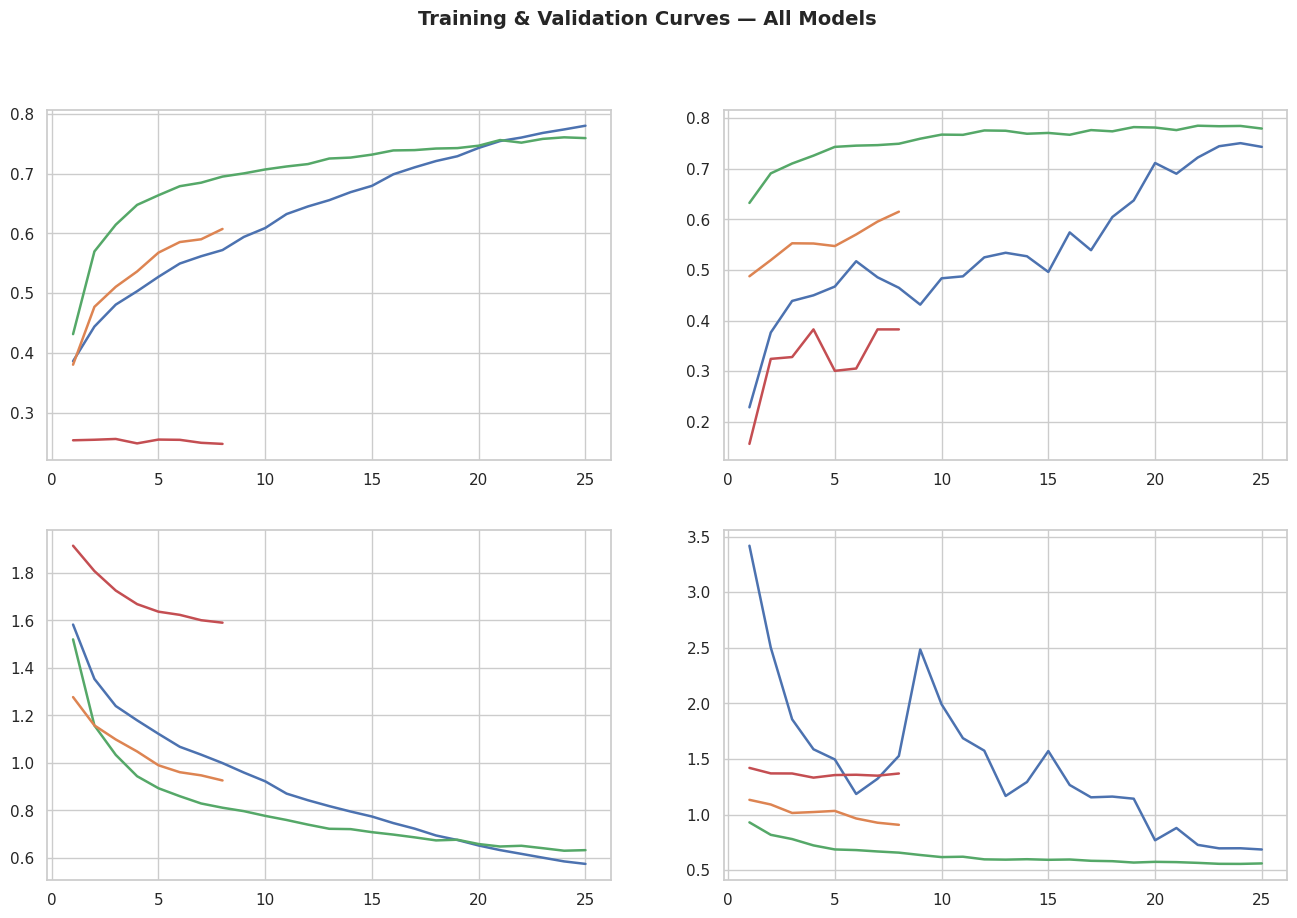

In [44]:
histories = {
    'Custom CNN':      cnn_history,
    'DenseNet169':     densenet_history,
    'EfficientNetB0':  efficientnet_history,
    'Vision Transformer': vit_history
}

colors_map = {
    'Custom CNN':         '#4C72B0',
    'DenseNet169':        '#55A868',
    'EfficientNetB0':     '#C44E52',
    'Vision Transformer': '#DD8452'
}

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Training & Validation Curves — All Models", fontsize=14, fontweight='bold')

for model_name, hist in histories.items():
    col = colors_map[model_name]
    epochs_ran = range(1, len(hist.history['accuracy']) + 1)

    axes[0, 0].plot(epochs_ran, hist.history['accuracy'],     color=col, label=model_name, linewidth=1.8)
    axes[0, 1].plot(epochs_ran, hist.history['val_accuracy'], color=col, label=model_name, linewidth=1.8)
    axes[1, 0].plot(epochs_ran, hist.history['loss'],         color=col, label=model_name, linewidth=1.8)
    axes[1, 1].plot(epochs_ran, hist.history['val_loss'],     color=col, label=model_name, linewidth=1.8)

In [45]:
for ax, title, ylabel in zip(
    axes.flat,
    ['Train Accuracy', 'Val Accuracy', 'Train Loss', 'Val Loss'],
    ['Accuracy', 'Accuracy', 'Loss', 'Loss']
):
    ax.set_title(title, fontsize=12)
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("training_curves_all_models.png", bbox_inches='tight')
    plt.show()

<Figure size 640x480 with 0 Axes>

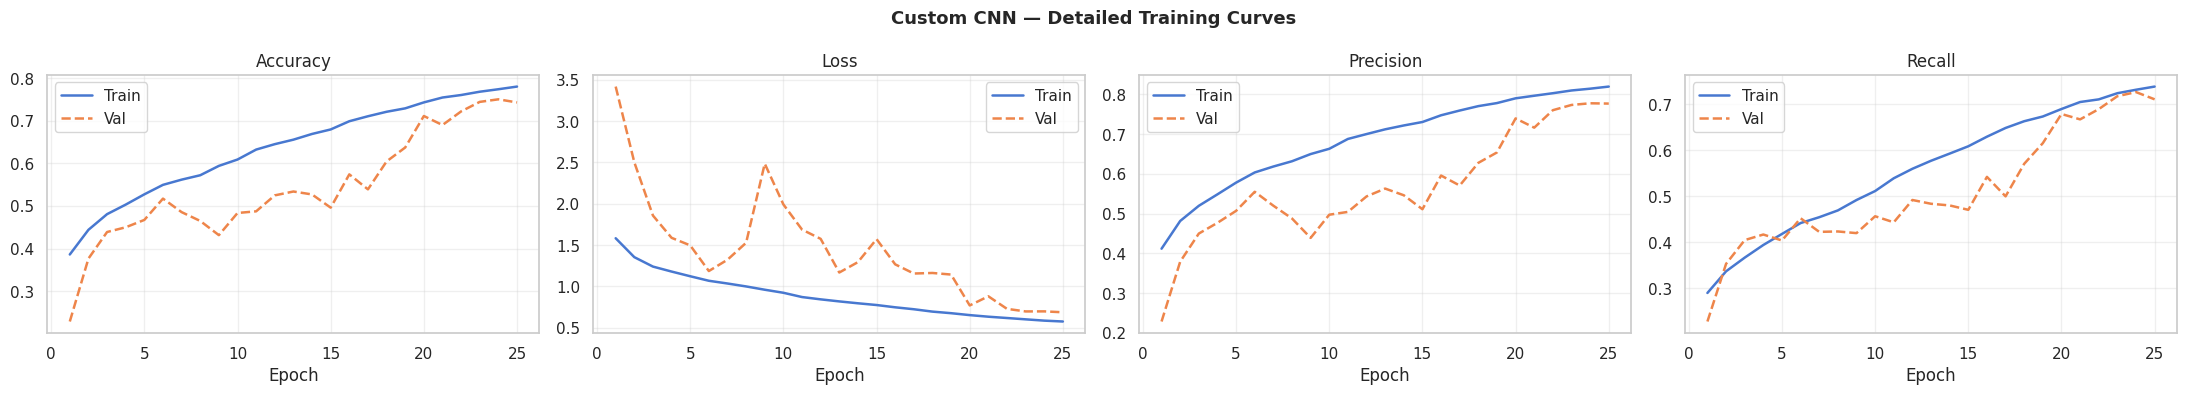

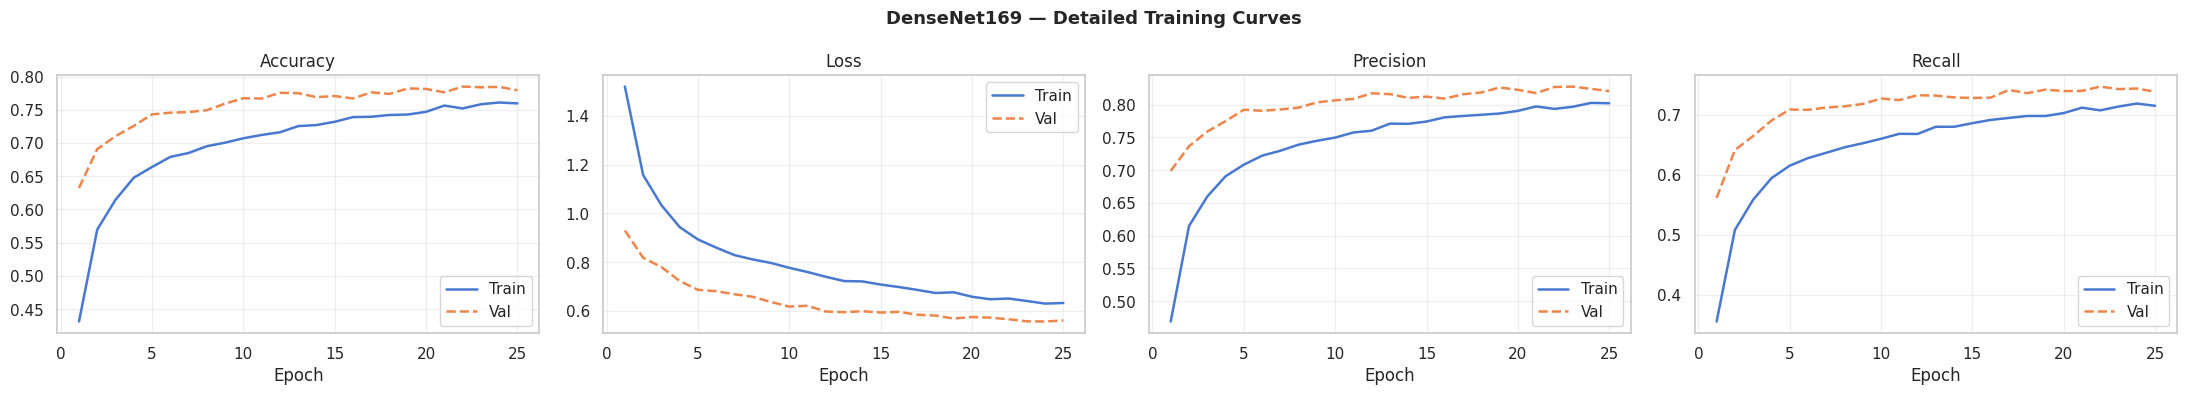

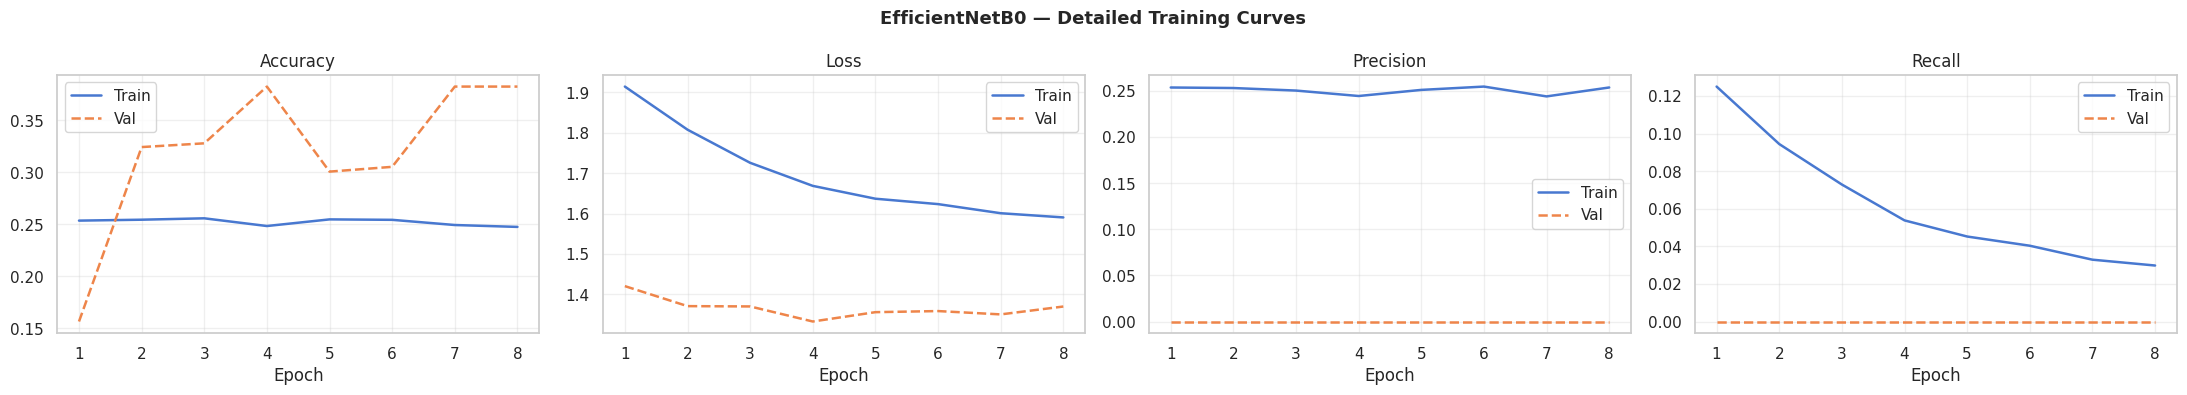

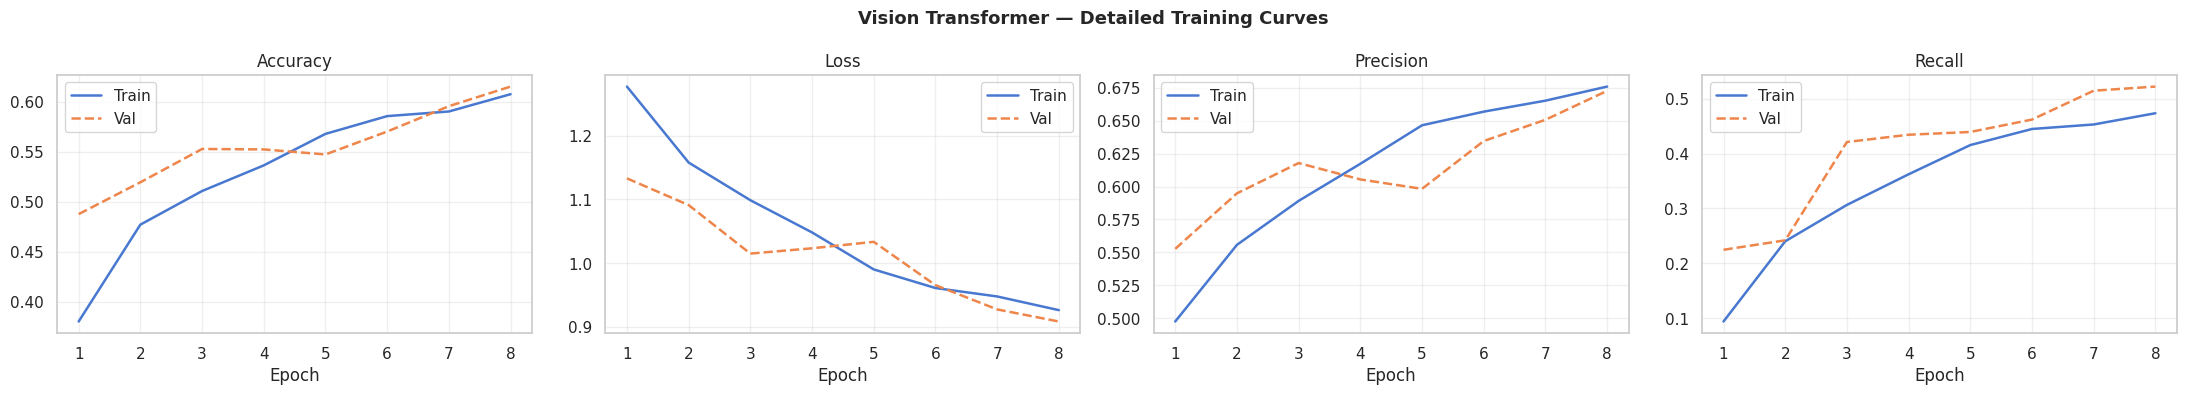

In [46]:
# Per-model detailed curves (Acc + Loss + Precision + Recall)
for model_name, hist in histories.items():
    h = hist.history
    fig, axes = plt.subplots(1, 4, figsize=(22, 4))
    fig.suptitle(f"{model_name} — Detailed Training Curves", fontsize=13, fontweight='bold')
    metrics_pairs = [
        ('accuracy', 'val_accuracy', 'Accuracy'),
        ('loss',     'val_loss',     'Loss'),
        ('precision','val_precision','Precision'),
        ('recall',   'val_recall',   'Recall')
    ]
    for ax, (tr, vl, lbl) in zip(axes, metrics_pairs):
        ep = range(1, len(h[tr]) + 1)
        ax.plot(ep, h[tr], label='Train', linewidth=1.8)
        ax.plot(ep, h[vl], label='Val',   linewidth=1.8, linestyle='--')
        ax.set_title(lbl)
        ax.set_xlabel('Epoch')
        ax.legend()
        ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"training_detailed_{model_name.replace(' ','_')}.png", bbox_inches='tight')
    plt.show()

## **Evaluation on Validation Set**

In [47]:
model_registry = {
    'Custom CNN':         cnn_model,
    'DenseNet169':        densenet_model,
    'EfficientNetB0':     efficientnet_model,
    'Vision Transformer': vit_model
}

In [48]:
all_metrics = []

def full_evaluate(model, model_name, generator, class_names):
    generator.reset()
    results = model.evaluate(generator, verbose=0)
    preds   = model.predict(generator, verbose=0)
    pred_labels = np.argmax(preds, axis=1)
    true_labels = generator.classes

    kappa = cohen_kappa_score(true_labels, pred_labels)
    mcc   = matthews_corrcoef(true_labels, pred_labels)

    return {
        'Model':     model_name,
        'Loss':      round(results[0], 4),
        'Accuracy':  round(results[1], 4),
        'Precision': round(results[2], 4),
        'Recall':    round(results[3], 4),
        'F1-Score':  round(results[4], 4),
        'Cohen Kappa': round(kappa, 4),
        'MCC':       round(mcc, 4),
        '_preds':    preds,
        '_pred_labels': pred_labels,
        '_true_labels': true_labels
    }

In [49]:
eval_results = {}
for name, model in model_registry.items():
    print(f"  Evaluating {name}...")
    result = full_evaluate(model, name, val_gen, CLASS_NAMES)
    eval_results[name] = result
    row = {k: v for k, v in result.items() if not k.startswith('_')}
    all_metrics.append(row)

metrics_df = pd.DataFrame(all_metrics)
print("Validation Metrics Summary:")
print(metrics_df.to_string(index=False))

  Evaluating Custom CNN...
  Evaluating DenseNet169...
  Evaluating EfficientNetB0...
  Evaluating Vision Transformer...
Validation Metrics Summary:
             Model   Loss  Accuracy  Precision  Recall  F1-Score  Cohen Kappa    MCC
        Custom CNN 0.6865    0.7430     0.7765  0.7103    0.7234       0.6366 0.6387
       DenseNet169 0.5569    0.7844     0.8240  0.7433    0.7661       0.6989 0.6997
    EfficientNetB0 1.4204    0.1565     0.0000  0.0000    0.0677       0.0000 0.0000
Vision Transformer 1.1331    0.4875     0.5527  0.2245    0.4709       0.2990 0.3081


In [64]:
metrics_df

,Model,Loss,Accuracy,Precision,Recall,F1-Score,Cohen Kappa,MCC
0,Custom CNN,0.6865,0.7430,0.7765,0.7103,0.7234,0.6366,0.6387
1,DenseNet169,0.5569,0.7844,0.8240,0.7433,0.7661,0.6989,0.6997
2,EfficientNetB0,1.4204,0.1565,0.0000,0.0000,0.0677,0.0000,0.0000
3,Vision Transformer,1.1331,0.4875,0.5527,0.2245,0.4709,0.2990,0.3081


#### **Metric Comparison Bar Chart**

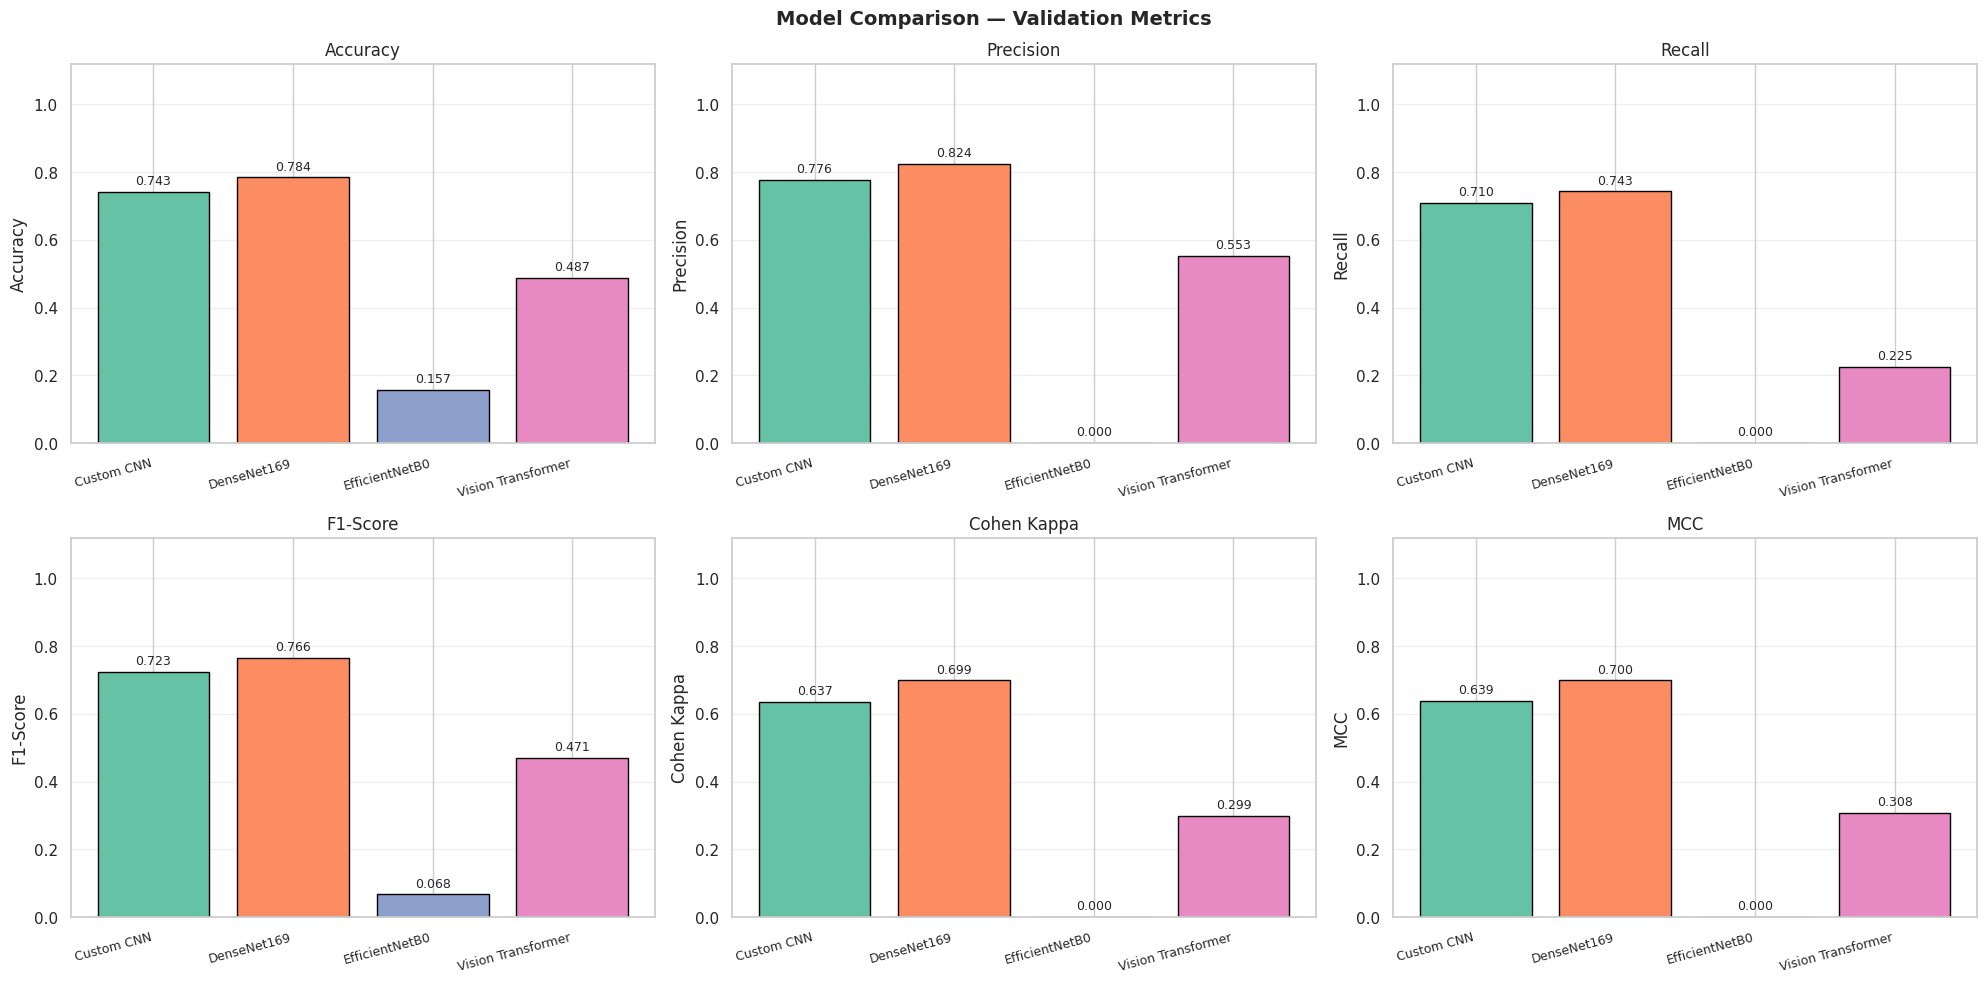

In [50]:
metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Cohen Kappa', 'MCC']

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
fig.suptitle("Model Comparison — Validation Metrics", fontsize=14, fontweight='bold')

pal = sns.color_palette("Set2", len(metrics_df))

for ax, metric in zip(axes.flat, metric_cols):
    bars = ax.bar(metrics_df['Model'], metrics_df[metric], color=pal, edgecolor='black')
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
    ax.set_title(metric, fontsize=12)
    ax.set_ylabel(metric)
    ax.set_ylim(0, 1.12)
    ax.set_xticklabels(metrics_df['Model'], rotation=15, ha='right', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig("eval_metric_comparison.png", bbox_inches='tight')
plt.show()

#### **Radar Chart**

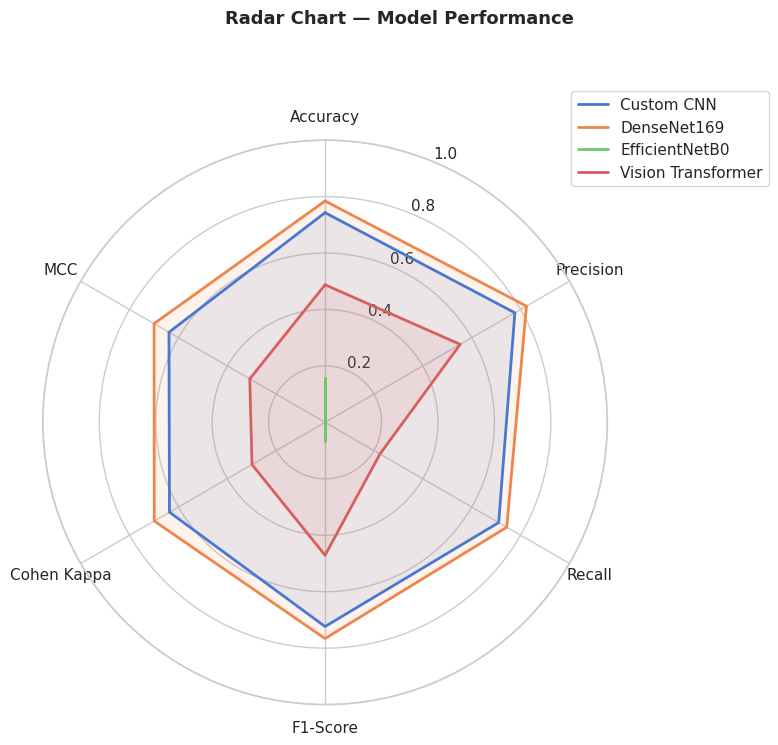

In [51]:
radar_metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Cohen Kappa', 'MCC']
N = len(radar_metrics)
angles = np.linspace(0, 2 * np.pi, N, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
fig.suptitle("Radar Chart — Model Performance", fontsize=13, fontweight='bold')

for i, row in metrics_df.iterrows():
    values = [max(0, row[m]) for m in radar_metrics]
    values += values[:1]
    ax.plot(angles, values, linewidth=2, label=row['Model'])
    ax.fill(angles, values, alpha=0.1)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), radar_metrics)
ax.set_ylim(0, 1)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.savefig("eval_radar_chart.png", bbox_inches='tight')
plt.show()

#### **Confusion Matrices**

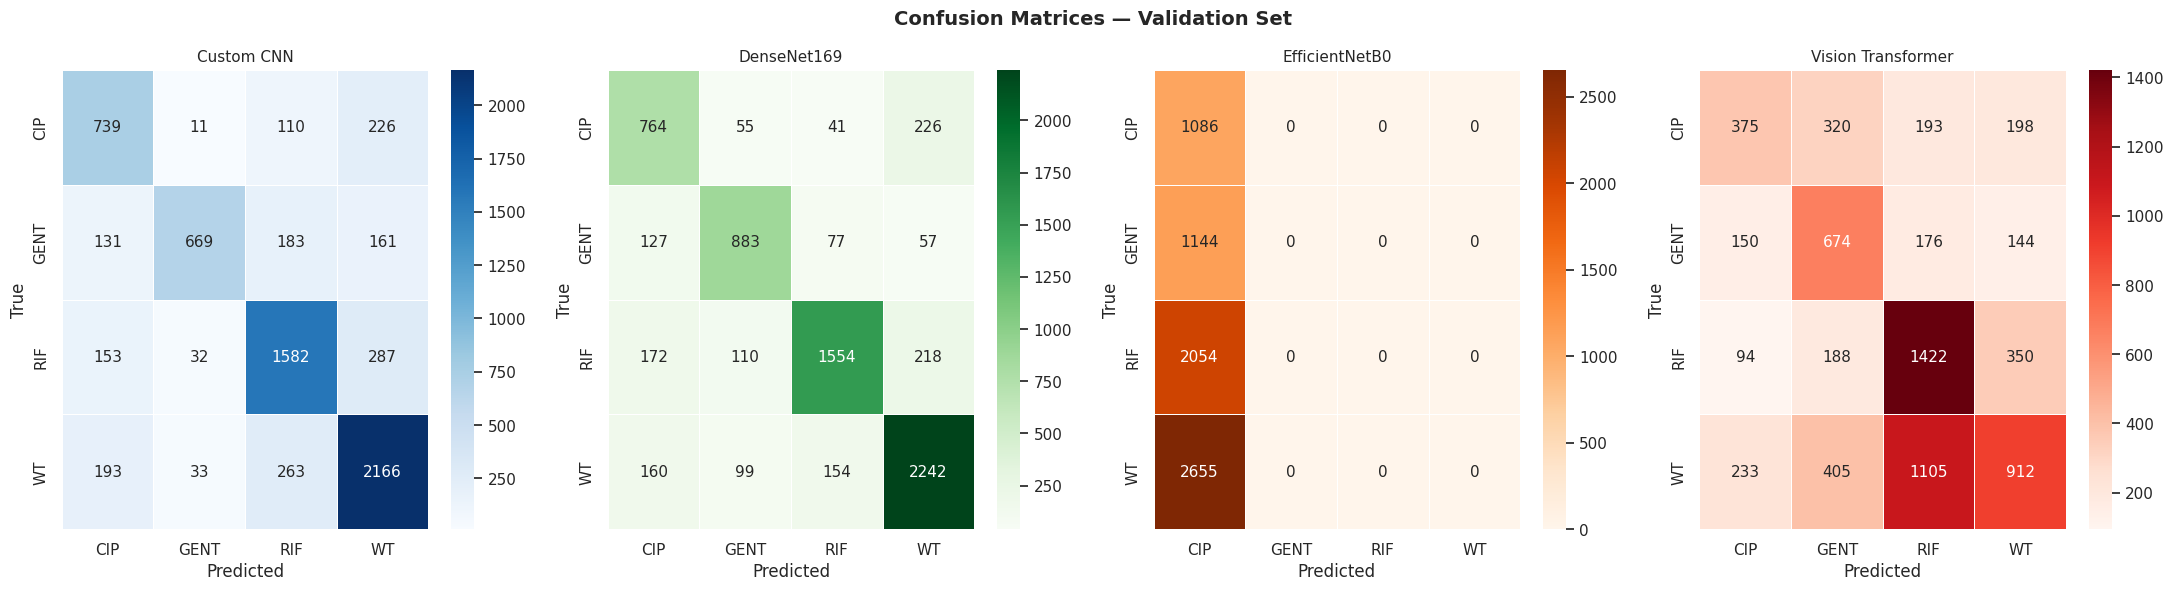

In [52]:
fig, axes = plt.subplots(1, len(model_registry), figsize=(22, 6))
fig.suptitle("Confusion Matrices — Validation Set", fontsize=14, fontweight='bold')
cmaps_list = ['Blues', 'Greens', 'Oranges', 'Reds']

for ax, (name, result), cmap in zip(axes, eval_results.items(), cmaps_list):
    cm = confusion_matrix(result['_true_labels'], result['_pred_labels'])
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax, cbar=True,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.tight_layout()
plt.savefig("eval_confusion_matrices.png", bbox_inches='tight')
plt.show()

#### **Normalised Confusion Matrices**

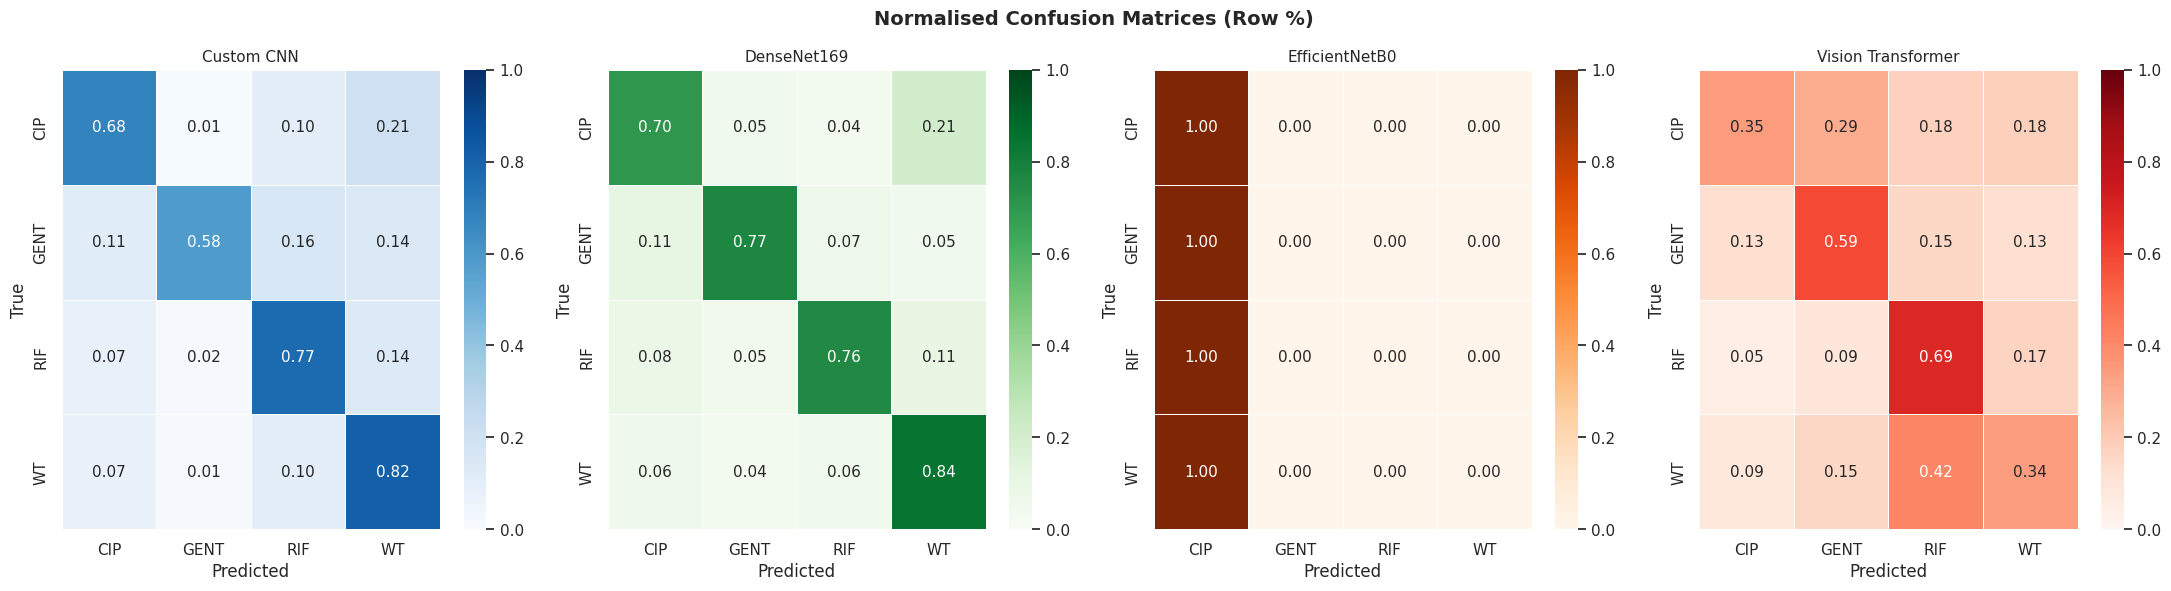

In [53]:
fig, axes = plt.subplots(1, len(model_registry), figsize=(22, 6))
fig.suptitle("Normalised Confusion Matrices (Row %)", fontsize=14, fontweight='bold')

for ax, (name, result), cmap in zip(axes, eval_results.items(), cmaps_list):
    cm   = confusion_matrix(result['_true_labels'], result['_pred_labels'])
    cm_n = cm.astype('float') / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_n, annot=True, fmt='.2f', cmap=cmap, ax=ax, vmin=0, vmax=1,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5)
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.tight_layout()
plt.savefig("eval_normalised_confusion_matrices.png", bbox_inches='tight')
plt.show()

#### **Per-Class Precision / Recall / F1**

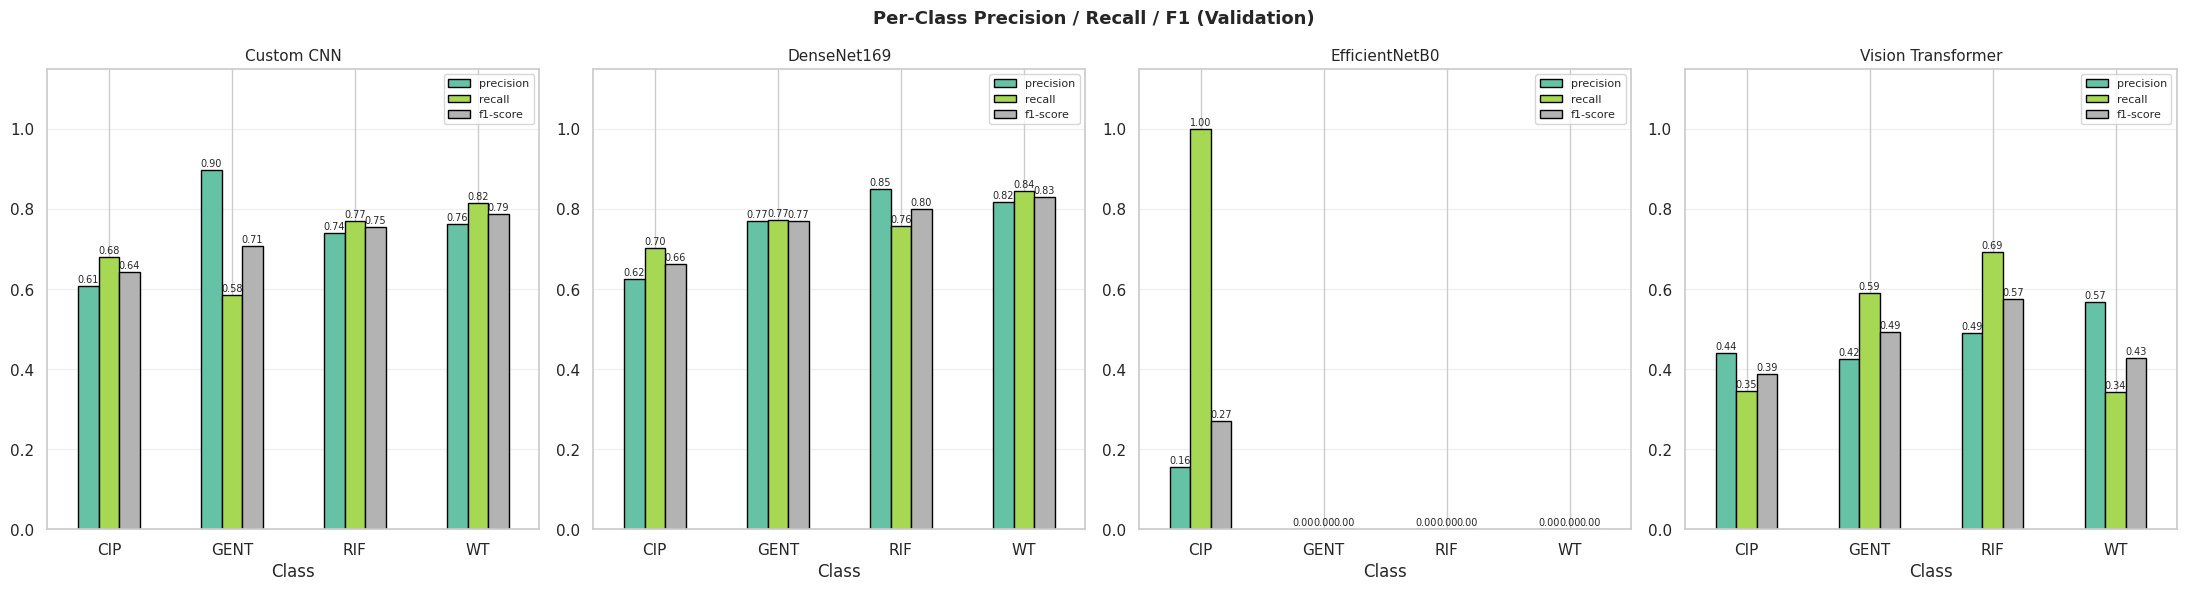

In [54]:
fig, axes = plt.subplots(1, len(model_registry), figsize=(22, 6))
fig.suptitle("Per-Class Precision / Recall / F1 (Validation)", fontsize=13, fontweight='bold')

for ax, (name, result) in zip(axes, eval_results.items()):
    report = classification_report(
        result['_true_labels'], result['_pred_labels'],
        target_names=CLASS_NAMES, output_dict=True, zero_division=0
    )
    per_class = pd.DataFrame({cls: report[cls] for cls in CLASS_NAMES}).T[['precision','recall','f1-score']]
    per_class.plot(kind='bar', ax=ax, colormap='Set2', edgecolor='black')
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("Class")
    ax.set_ylim(0, 1.15)
    ax.set_xticklabels(CLASS_NAMES, rotation=0)
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', padding=1, fontsize=7)

plt.tight_layout()
plt.savefig("eval_per_class_metrics.png", bbox_inches='tight')
plt.show()

#### **Classification Reports**

In [55]:
print("Classification Reports:")
for name, result in eval_results.items():
    print(f"\n{'─'*55}")
    print(f"  {name}")
    print('─'*55)
    print(classification_report(
        result['_true_labels'], result['_pred_labels'],
        target_names=CLASS_NAMES, zero_division=0
    ))

Classification Reports:

───────────────────────────────────────────────────────
  Custom CNN
───────────────────────────────────────────────────────
              precision    recall  f1-score   support

         CIP       0.61      0.68      0.64      1086
        GENT       0.90      0.58      0.71      1144
         RIF       0.74      0.77      0.75      2054
          WT       0.76      0.82      0.79      2655

    accuracy                           0.74      6939
   macro avg       0.75      0.71      0.72      6939
weighted avg       0.75      0.74      0.74      6939


───────────────────────────────────────────────────────
  DenseNet169
───────────────────────────────────────────────────────
              precision    recall  f1-score   support

         CIP       0.62      0.70      0.66      1086
        GENT       0.77      0.77      0.77      1144
         RIF       0.85      0.76      0.80      2054
          WT       0.82      0.84      0.83      2655

    accuracy    

#### **ROC-AUC Curves**

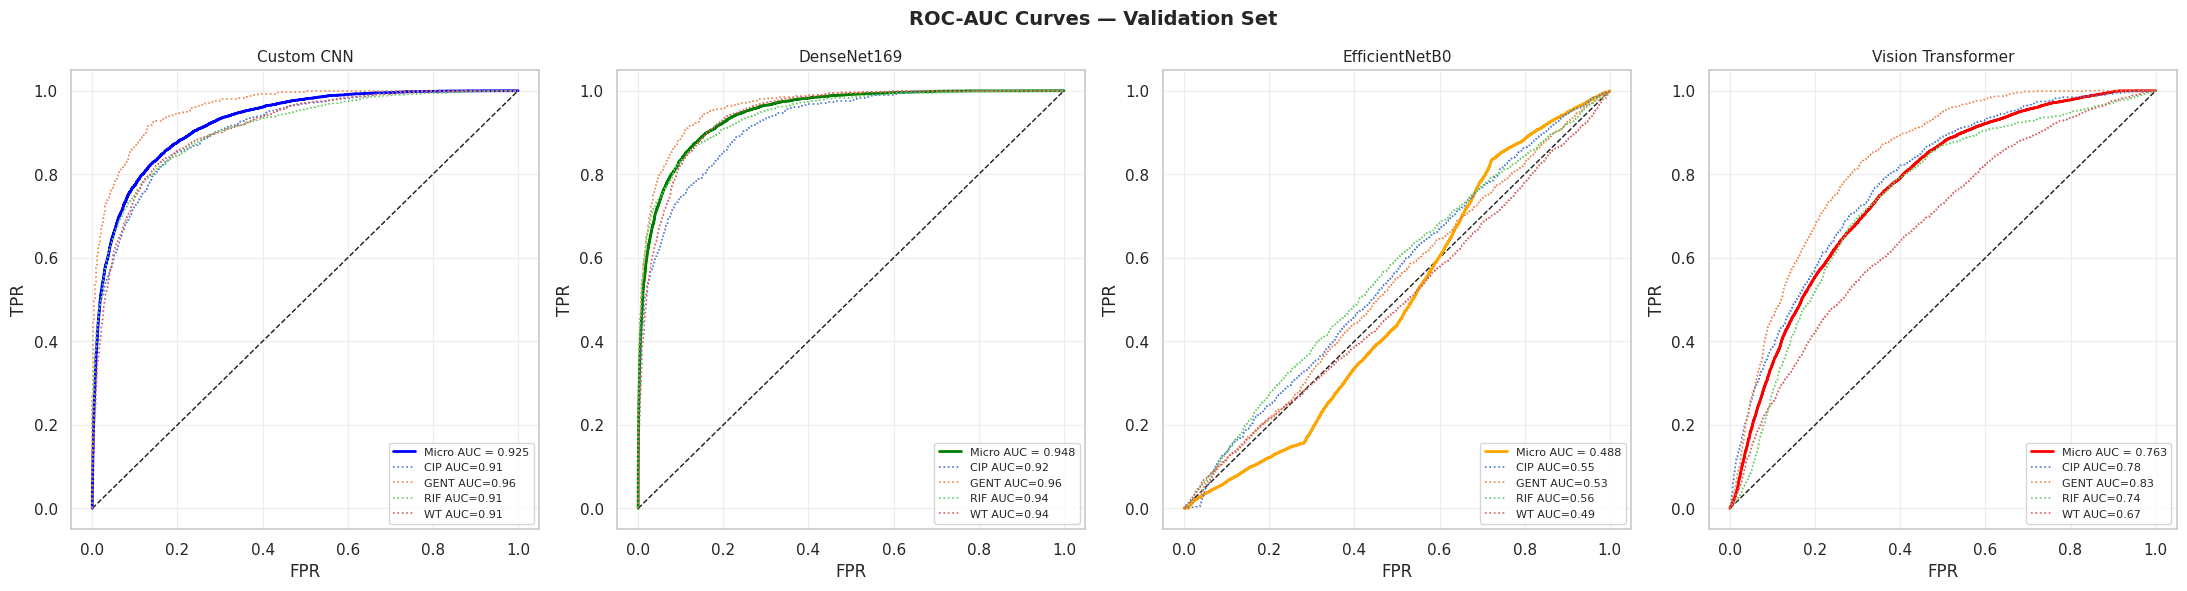

In [56]:
val_gen.reset()
lb = LabelBinarizer()
lb.fit(val_gen.classes)
true_bin = lb.transform(val_gen.classes)

fig, axes = plt.subplots(1, len(model_registry), figsize=(22, 6))
fig.suptitle("ROC-AUC Curves — Validation Set", fontsize=14, fontweight='bold')
line_colors = ['blue', 'green', 'orange', 'red']

for ax, (name, result), lc in zip(axes, eval_results.items(), line_colors):
    preds = result['_preds']

    # Micro-average
    fpr_m, tpr_m, _ = roc_curve(true_bin.ravel(), preds.ravel())
    auc_m = auc(fpr_m, tpr_m)

    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.plot(fpr_m, tpr_m, color=lc, lw=2, label=f'Micro AUC = {auc_m:.3f}')

    # Per-class curves
    for cls_idx, cls_name in enumerate(CLASS_NAMES):
        fpr_c, tpr_c, _ = roc_curve(true_bin[:, cls_idx], preds[:, cls_idx])
        auc_c = auc(fpr_c, tpr_c)
        ax.plot(fpr_c, tpr_c, lw=1.2, linestyle=':', label=f'{cls_name} AUC={auc_c:.2f}')

    ax.set_title(name, fontsize=11)
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.legend(fontsize=8, loc='lower right')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("eval_roc_auc_curves.png", bbox_inches='tight')
plt.show()

## **Test Set Evaluation using Best Model**

In [57]:
best_row = metrics_df.loc[metrics_df['F1-Score'].idxmax()]
best_name = best_row['Model']
best_model = model_registry[best_name]
print(f"Best Model (by Val F1): {best_name}  (F1 = {best_row['F1-Score']:.4f})")

Best Model (by Val F1): DenseNet169  (F1 = 0.7661)


Test Set Results — DenseNet169:
            Model: DenseNet169
             Loss: 0.5514
         Accuracy: 0.7856
        Precision: 0.8303
           Recall: 0.7436
         F1-Score: 0.7737
      Cohen Kappa: 0.7062
              MCC: 0.7067


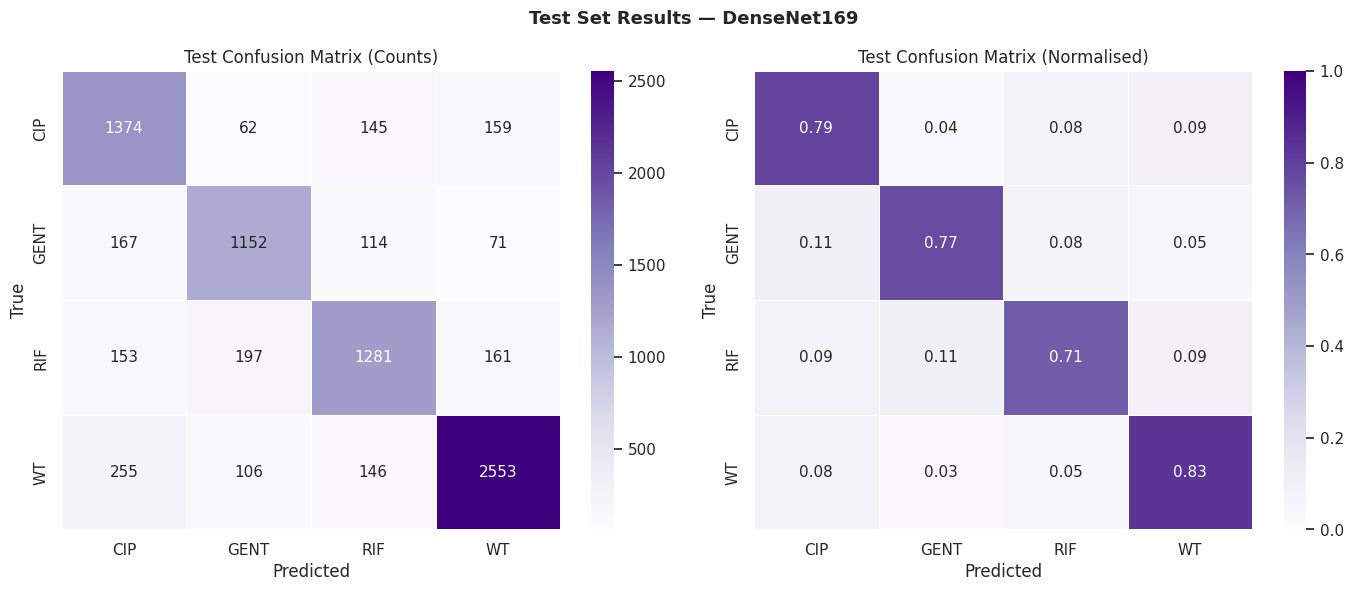

In [58]:
# Evaluate on test set
test_gen.reset()
test_result = full_evaluate(best_model, best_name, test_gen, CLASS_NAMES)

print(f"Test Set Results — {best_name}:")
for k, v in test_result.items():
    if not k.startswith('_'):
        print(f"  {k:>15s}: {v}")

# Test Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(f"Test Set Results — {best_name}", fontsize=13, fontweight='bold')

cm_test   = confusion_matrix(test_result['_true_labels'], test_result['_pred_labels'])
cm_test_n = cm_test.astype('float') / cm_test.sum(axis=1, keepdims=True)

sns.heatmap(cm_test, annot=True, fmt='d', cmap='Purples', ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5)
axes[0].set_title("Test Confusion Matrix (Counts)")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("True")

sns.heatmap(cm_test_n, annot=True, fmt='.2f', cmap='Purples', ax=axes[1],
            vmin=0, vmax=1, xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5)
axes[1].set_title("Test Confusion Matrix (Normalised)")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("True")

plt.tight_layout()
plt.savefig("test_confusion_matrix.png", bbox_inches='tight')
plt.show()

In [59]:
print(f"Test Classification Report — {best_name}:")
print(classification_report(
    test_result['_true_labels'], test_result['_pred_labels'],
    target_names=CLASS_NAMES, zero_division=0
))

Test Classification Report — DenseNet169:
              precision    recall  f1-score   support

         CIP       0.70      0.79      0.74      1740
        GENT       0.76      0.77      0.76      1504
         RIF       0.76      0.71      0.74      1792
          WT       0.87      0.83      0.85      3060

    accuracy                           0.79      8096
   macro avg       0.77      0.78      0.77      8096
weighted avg       0.79      0.79      0.79      8096



## **Qualitative Predictions**

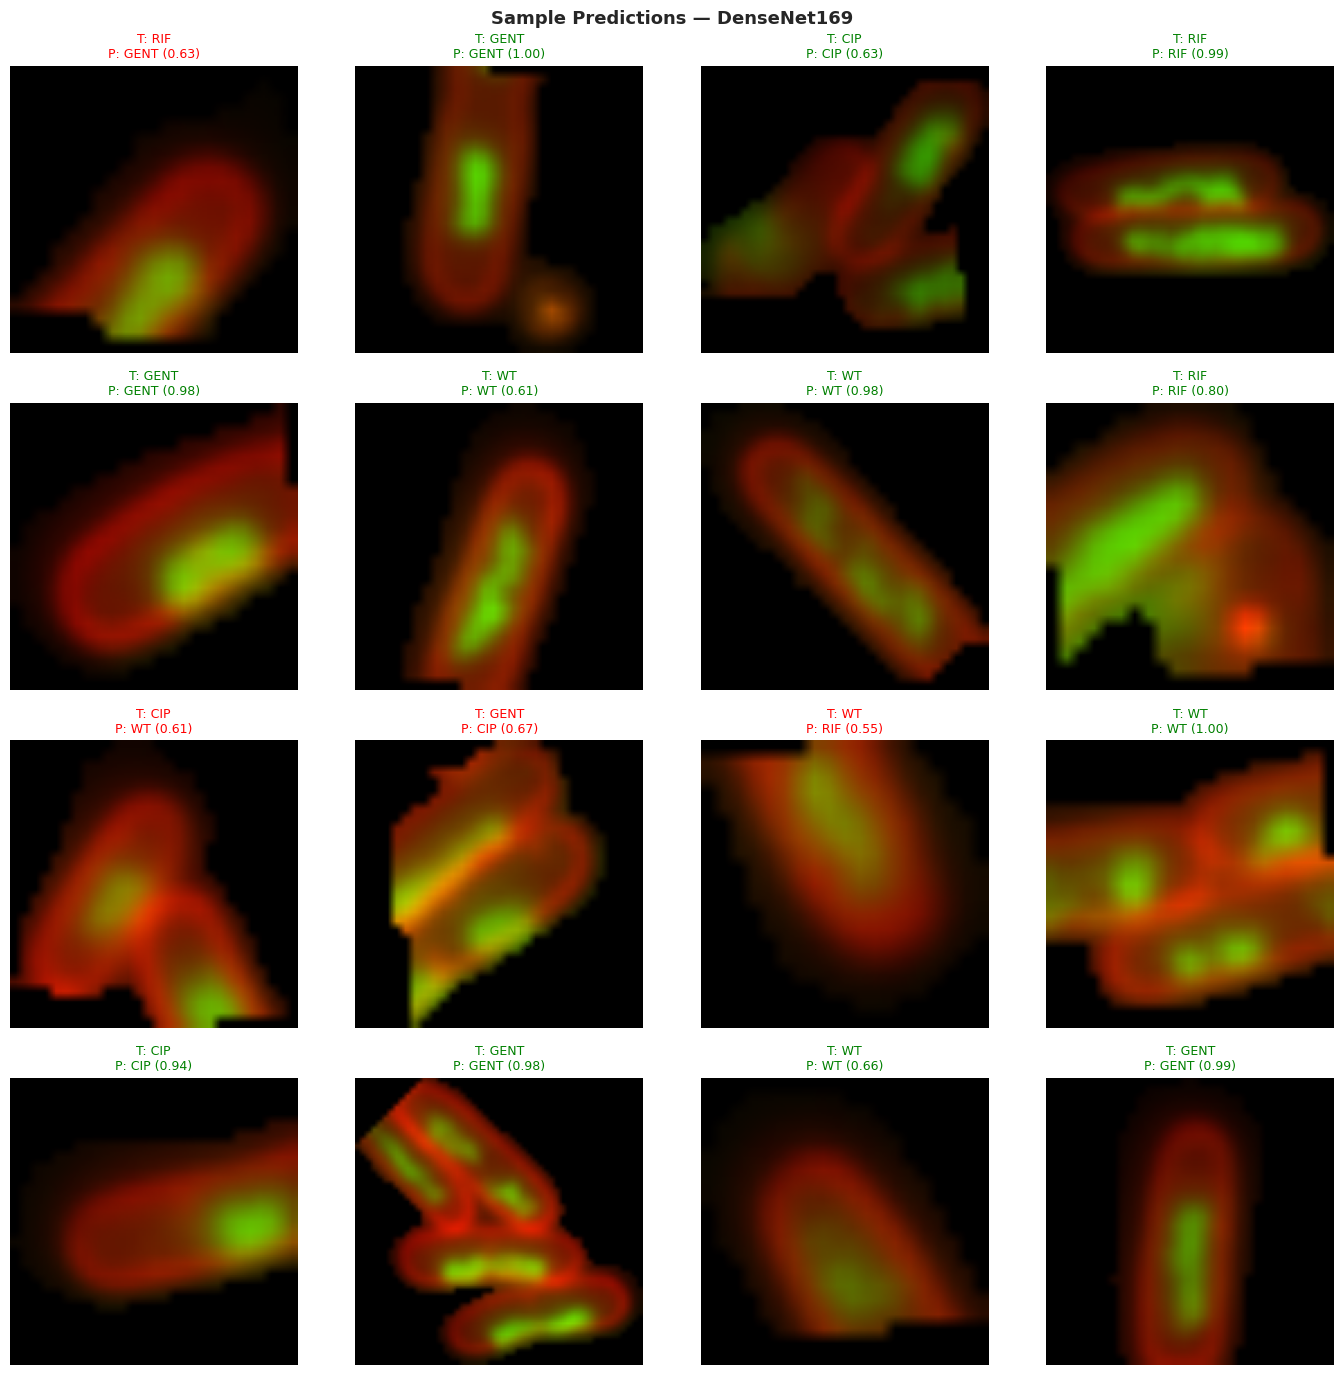

In [60]:
test_seg_dir = 'segmented images/test_segmented'
all_test_imgs = []

for cls_label in os.listdir(test_seg_dir):
    cls_path = os.path.join(test_seg_dir, cls_label)
    if os.path.isdir(cls_path):
        for fn in os.listdir(cls_path):
            if fn.lower().endswith('.png'):
                all_test_imgs.append((os.path.join(cls_path, fn), cls_label))

n_show = min(16, len(all_test_imgs))
selected = random.sample(all_test_imgs, n_show)

fig, axes = plt.subplots(4, 4, figsize=(14, 14))
fig.suptitle(f"Sample Predictions — {best_name}", fontsize=13, fontweight='bold')

# Map index → class name
idx_to_class = {v: k for k, v in train_gen.class_indices.items()}

for ax, (img_path, true_label) in zip(axes.flat, selected):
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    inp = cv2.resize(img_rgb, IMAGE_SIZE) / 255.0
    inp = np.expand_dims(inp, 0)

    prob = best_model.predict(inp, verbose=0)
    pred_idx = np.argmax(prob)
    pred_label = idx_to_class[pred_idx]
    conf = prob[0, pred_idx]

    color = 'green' if pred_label == true_label else 'red'
    ax.imshow(img_rgb)
    ax.set_title(f"T: {true_label}\nP: {pred_label} ({conf:.2f})",
                 color=color, fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.savefig("qualitative_predictions.png", bbox_inches='tight')
plt.show()

## **Summary Table**

In [61]:
summary_cols = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'Cohen Kappa', 'MCC']
summary_df = metrics_df[summary_cols].sort_values('F1-Score', ascending=False).reset_index(drop=True)
summary_df.index += 1  # rank from 1

print("Final Leaderboard (Validation Set — sorted by F1-Score):")
print(summary_df.to_string())

Final Leaderboard (Validation Set — sorted by F1-Score):
                Model  Accuracy  Precision  Recall  F1-Score  Cohen Kappa     MCC
1         DenseNet169    0.7844     0.8240  0.7433    0.7661       0.6989  0.6997
2          Custom CNN    0.7430     0.7765  0.7103    0.7234       0.6366  0.6387
3  Vision Transformer    0.4875     0.5527  0.2245    0.4709       0.2990  0.3081
4      EfficientNetB0    0.1565     0.0000  0.0000    0.0677       0.0000  0.0000


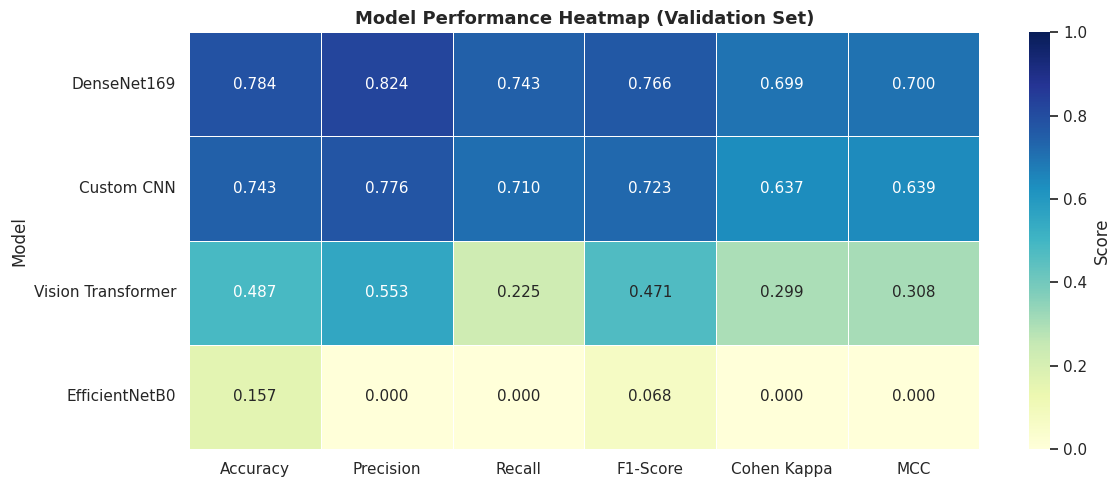

In [62]:
# Heatmap of all scores
fig, ax = plt.subplots(figsize=(12, 5))
heat_data = summary_df.set_index('Model')[['Accuracy','Precision','Recall','F1-Score','Cohen Kappa','MCC']]
sns.heatmap(heat_data, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0, vmax=1,
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Score'})
ax.set_title("Model Performance Heatmap (Validation Set)", fontsize=13, fontweight='bold')
ax.set_ylabel("Model")
plt.tight_layout()
plt.savefig("final_leaderboard_heatmap.png", bbox_inches='tight')
plt.show()

In [63]:
print("Pipeline complete. All plots saved as PNG files.")
print(f"Best Model: {best_name}")
print(f"   Val Accuracy  : {best_row['Accuracy']:.4f}")
print(f"   Val F1-Score  : {best_row['F1-Score']:.4f}")
print(f"   Val Cohen Kappa: {best_row['Cohen Kappa']:.4f}")
print(f"   Val MCC       : {best_row['MCC']:.4f}")

Pipeline complete. All plots saved as PNG files.
Best Model: DenseNet169
   Val Accuracy  : 0.7844
   Val F1-Score  : 0.7661
   Val Cohen Kappa: 0.6989
   Val MCC       : 0.6997
